### Import the packages ###

In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')

### Import the datasets ###

In [117]:
# Import data

server=r'DESKTOP-D627T83\SQLEXPRESS'
database='INTERNSHIP'

connection_string=f"mssql+pyodbc://@{server}/{database}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"

engine=create_engine(connection_string)

In [118]:
query1="select * from orders_flagged"
orders=pd.read_sql(query1,con=engine)

query2="select * from customer"
customer=pd.read_sql(query2,con=engine)

query3="SELECT geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,TRANSLATE(geolocation_city,\
'áàâãäéèêëíìîïóòôõöúùûüçÁÀÂÃÄÉÈÊËÍÌÎÏÓÒÔÕÖÚÙÛÜÇ','aaaaaeeeeiiiiooooouuuucAAAAAEEEEIIIIOOOOOUUUUC') \
AS geolocation_city,geolocation_state FROM geolocation_temp"
geolocation=pd.read_sql(query3,con=engine)

query4="select * from order_items"
order_items=pd.read_sql(query4,con=engine)

query5="select * from order_payments_clean"
order_payments=pd.read_sql(query5,con=engine)

query6="select * from order_reviews_clean"
order_reviews=pd.read_sql(query6,con=engine)

query7="select * from product_category_name_translation"
product_category=pd.read_sql(query7,con=engine)

query8="select * from products_clean"
products=pd.read_sql(query8,con=engine)

query9="select * from sellers"
sellers=pd.read_sql(query9,con=engine)

In [119]:
order_payments_old=pd.read_csv(r"C:\Users\HP Victus\Desktop\AnalytixLabs\Internship\PRP Cohort 4 Project 1 - 1791804190055\2. Data\order_payments.csv")

### Last cleaning step ###

In [120]:
geolocation_new=geolocation.groupby('geolocation_zip_code_prefix')[['geolocation_lat','geolocation_lng','geolocation_city','geolocation_state']].agg(
    geolocation_lat=('geolocation_lat','mean'),
    geolocation_lng=('geolocation_lng','mean'),
    geolocation_city=('geolocation_city','max'),
    geolocation_state=('geolocation_state','max')).reset_index()

### Check imported data ###

In [121]:
customer.head(3)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,00012a2ce6f8dcda20d059ce98491703,248ffe10d632bebe4f7267f1f44844c9,6273,osasco,SP
1,000161a058600d5901f007fab4c27140,b0015e09bb4b6e47c52844fab5fb6638,35550,itapecerica,MG
2,0001fd6190edaaf884bcaf3d49edf079,94b11d37cd61cb2994a194d11f89682b,29830,nova venecia,ES


In [122]:
orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,date_inconsistency_flag
0,a9fd47117c3f6b4e72456d5331e2bfb1,779609a1ecaee6f5ea1b6e50359c0aa1,delivered,2018-02-01 15:10:00,2018-02-01 15:34:00,2018-02-05 21:43:00,2018-02-14 22:36:00,2018-02-23,0
1,b62fb8675350e9d26562d21d74f310bc,196589770e3a1f3bec937543f965046b,delivered,2018-04-27 15:42:00,2018-05-01 05:32:00,2018-05-02 15:20:00,2018-05-08 19:44:00,2018-05-22,0
2,3de92648437ce8d6e9d3b60f36cfa537,92ff4a1cd03e989698328acb4c3fc46c,delivered,2018-05-02 20:47:00,2018-05-02 21:18:00,2018-05-08 12:25:00,2018-05-14 16:19:00,2018-05-30,0


In [123]:
geolocation_new.head(3)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1001,-23.550271,-46.634047,sao paulo,SP
1,1002,-23.547657,-46.634991,sao paulo,SP
2,1003,-23.548991,-46.635653,sao paulo,SP


In [124]:
order_items.head(3)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.900002,13.290000
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.899994,19.930000
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.000000,17.870001


In [125]:
order_payments.head(3)

,order_id,tot_orders,Total_installments,credit_card,boleto,voucher,debit_card,others,total_amount
0,00010242fe8c5a6d1ba2dd792cb16214,1,2,72.19,0.0,0.0,0.0,0.0,72.19
1,00018f77f2f0320c557190d7a144bdd3,1,3,259.83,0.0,0.0,0.0,0.0,259.83
2,000229ec398224ef6ca0657da4fc703e,1,5,216.87,0.0,0.0,0.0,0.0,216.87


In [126]:
order_reviews.head(3)

,order_id,review_id,review_score,review_creation_date,review_answer_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,97ca439bc427b48bc1cd7177abe71365,5,2017-09-21,2017-09-22 10:57:00
1,00018f77f2f0320c557190d7a144bdd3,7b07bacd811c4117b742569b04ce3580,4,2017-05-13,2017-05-15 11:34:00
2,000229ec398224ef6ca0657da4fc703e,0c5b33dea94867d1ac402749e5438e8b,5,2018-01-23,2018-01-23 16:06:00


In [127]:
product_category.head(3)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


In [128]:
products.head(3)

,product_id,product_category_name,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,00066f42aeeb9f3007548bb9d3f33c38,perfumaria,6,300.0,20.0,16.0,16.0
1,00088930e925c41fd95ebfe695fd2655,automotivo,4,1225.0,55.0,10.0,26.0
2,0009406fd7479715e4bef61dd91f2462,cama_mesa_banho,2,300.0,45.0,15.0,35.0


In [129]:
sellers.head(3)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,0015a82c2db000af6aaaf3ae2ecb0532,9080,santo andre,SP
1,001cca7ae9ae17fb1caed9dfb1094831,29156,cariacica,ES
2,001e6ad469a905060d959994f1b41e4f,24754,sao goncalo,RJ


## Calculated fields ##

In [130]:
orders['order_approval_hours']=(orders['order_approved_at']-orders['order_purchase_timestamp']).dt.total_seconds()/3600
orders['carrier_delivered_days']=(orders['order_delivered_carrier_date']-orders['order_approved_at']).dt.days
orders['customer_delivered_days']=(orders['order_delivered_customer_date']-orders['order_delivered_carrier_date']).dt.days
orders['order_timely_delivered?']=np.where(orders['order_estimated_delivery_date']>=orders['order_delivered_customer_date'],'Yes','No')
orders['order_purchase_period']=orders['order_purchase_timestamp'].dt.to_period('M')

## Customer level Analysis ##

In [131]:
# Total customers

customer['customer_unique_id'].nunique()

96096

In [132]:
# Total customer zip codes

customer['customer_zip_code_prefix'].nunique()

14994

In [133]:
# Total customer city

customer['customer_city'].nunique()

4119

In [134]:
# Total customer state

customer['customer_state'].nunique()

27

### Total customers per state ###

In [135]:
customer.groupby('customer_state')['customer_unique_id'].count()

customer_state
AC       81
AL      413
AM      148
AP       68
BA     3380
CE     1336
DF     2140
ES     2033
GO     2020
MA      747
MG    11635
MS      715
MT      907
PA      975
PB      536
PE     1652
PI      495
PR     5045
RJ    12852
RN      485
RO      253
RR       46
RS     5466
SC     3637
SE      350
SP    41746
TO      280
Name: customer_unique_id, dtype: int64

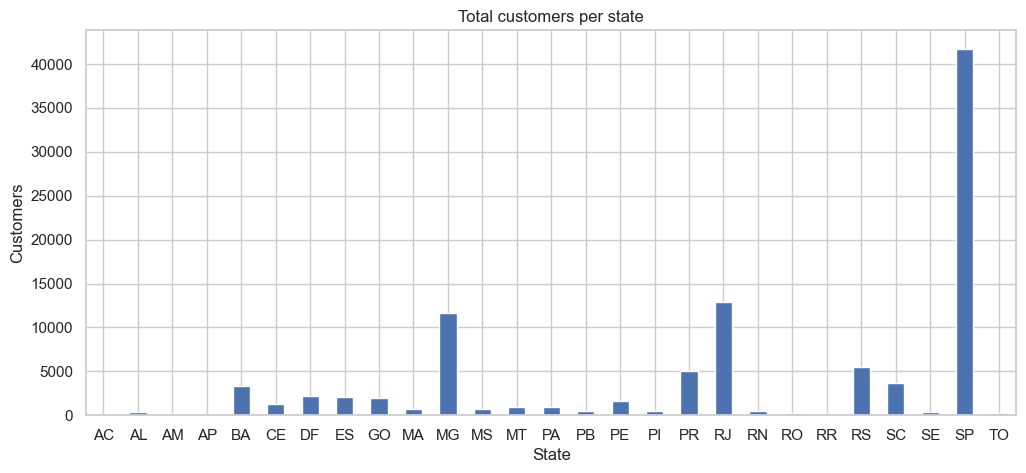

In [136]:
plt.figure(figsize=(12,5))
customer.groupby('customer_state')['customer_unique_id'].count().plot(kind='bar')
plt.title('Total customers per state')
plt.xlabel('State')
plt.ylabel('Customers')
plt.xticks(rotation=0)
plt.show()

### Top 10 cities with maximum number of customers ###

In [137]:
customer.groupby('customer_city')['customer_id'].count().sort_values(ascending=False).head(10)

customer_city
sao paulo                15540
rio de janeiro            6882
belo horizonte            2773
brasilia                  2131
curitiba                  1521
campinas                  1444
porto alegre              1379
salvador                  1245
guarulhos                 1189
sao bernardo do campo      938
Name: customer_id, dtype: int64

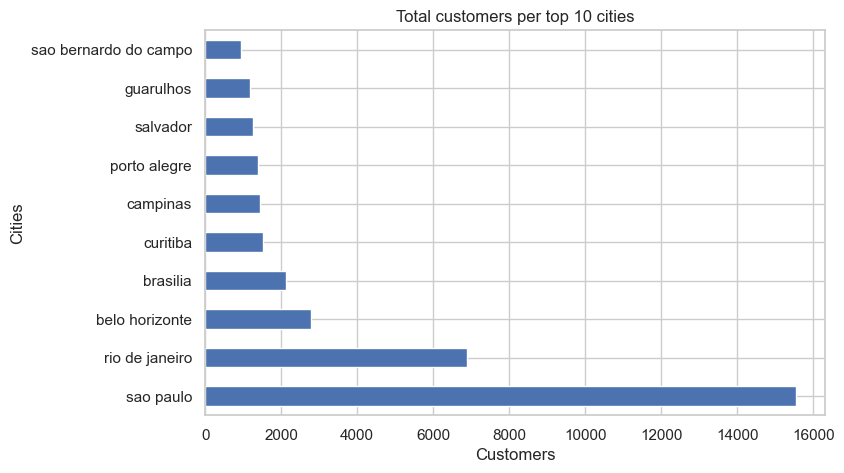

In [138]:
plt.figure(figsize=(8,5))
customer.groupby('customer_city')['customer_id'].count().sort_values(ascending=False).head(10).plot(kind='barh')
plt.title('Total customers per top 10 cities')
plt.xlabel('Customers')
plt.ylabel('Cities')
plt.show()

### Customer acquisition per month ###

In [139]:
new_customer_orders=pd.merge(orders,customer,on='customer_id',how='inner')
new_customer_orders.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,date_inconsistency_flag,order_approval_hours,carrier_delivered_days,customer_delivered_days,order_timely_delivered?,order_purchase_period,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,a9fd47117c3f6b4e72456d5331e2bfb1,779609a1ecaee6f5ea1b6e50359c0aa1,delivered,2018-02-01 15:10:00,2018-02-01 15:34:00,2018-02-05 21:43:00,2018-02-14 22:36:00,2018-02-23,0,0.400000,4.0,9.0,Yes,2018-02,abf1d6bd1161f2d55493942abb8c1402,14077,ribeirao preto,SP
1,b62fb8675350e9d26562d21d74f310bc,196589770e3a1f3bec937543f965046b,delivered,2018-04-27 15:42:00,2018-05-01 05:32:00,2018-05-02 15:20:00,2018-05-08 19:44:00,2018-05-22,0,85.833333,1.0,6.0,Yes,2018-04,384ffc528dd30fd49eff3dda9f00ce86,13875,sao joao da boa vista,SP
2,3de92648437ce8d6e9d3b60f36cfa537,92ff4a1cd03e989698328acb4c3fc46c,delivered,2018-05-02 20:47:00,2018-05-02 21:18:00,2018-05-08 12:25:00,2018-05-14 16:19:00,2018-05-30,0,0.516667,5.0,6.0,Yes,2018-05,daefb889f38f3b8b82e2b467a6a024e8,38015,uberaba,MG


In [140]:
# Customer first purchase

first_purchase=new_customer_orders.groupby('customer_unique_id')['order_purchase_period'].min().reset_index()
first_purchase

,customer_unique_id,order_purchase_period
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05
2,0000f46a3911fa3c0805444483337064,2017-03
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10
4,0004aac84e0df4da2b147fca70cf8255,2017-11
...,...,...
96091,fffcf5a5ff07b0908bd4e2dbc735a684,2017-06
96092,fffea47cd6d3cc0a88bd621562a9d061,2017-12
96093,ffff371b4d645b6ecea244b27531430a,2017-02
96094,ffff5962728ec6157033ef9805bacc48,2018-05


In [141]:
# Monthly acquisition

monthly_acq=first_purchase.groupby('order_purchase_period').size().reset_index(name='new_customer_count')
monthly_acq

,order_purchase_period,new_customer_count
0,2016-09,4
1,2016-10,321
2,2016-12,1
3,2017-01,764
4,2017-02,1752
5,2017-03,2636
6,2017-04,2352
7,2017-05,3596
8,2017-06,3139
9,2017-07,3894


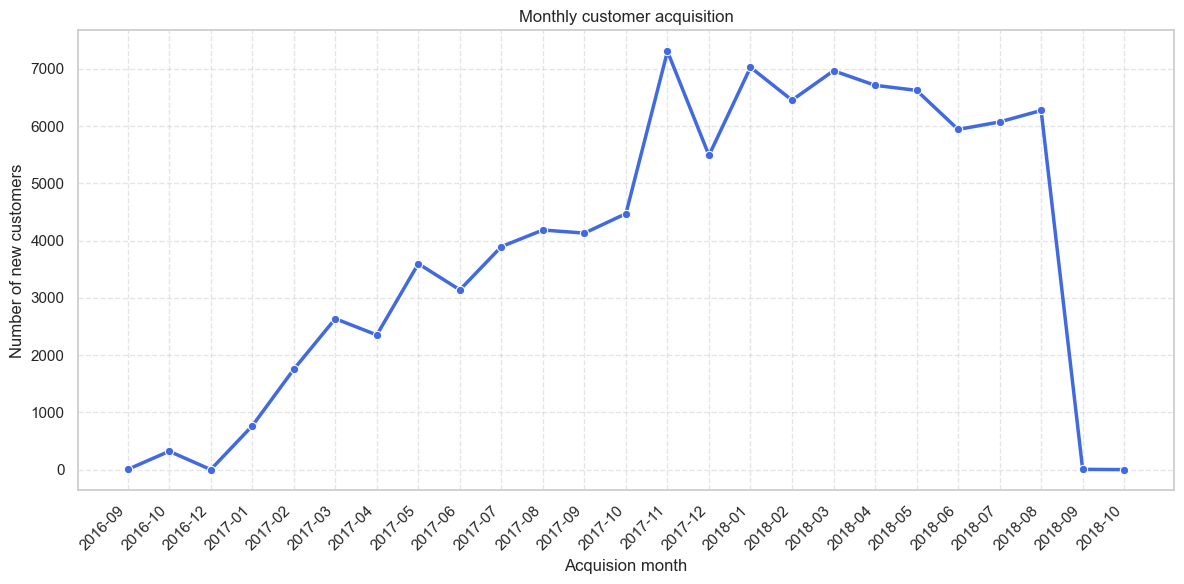

In [142]:
monthly_acq['order_purchase_period']=monthly_acq['order_purchase_period'].astype(str)

plt.figure(figsize=(12,6))
sns.set_theme(style='whitegrid')

sns.lineplot(data=monthly_acq,
             x='order_purchase_period',
             y='new_customer_count',
             marker='o',
             color='royalblue',
             linewidth=2.5,
             markersize=6)

plt.title('Monthly customer acquisition')
plt.xlabel('Acquision month')
plt.ylabel('Number of new customers')
plt.xticks(rotation=45,ha='right')
plt.grid(True,linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

### RFM Segmentation ###

In [143]:
# Join Customer, Orders & Order_payments

temp_df=pd.merge(orders,customer,on='customer_id',how='inner')
order_cust_payments=pd.merge(temp_df,order_payments_old,on='order_id',how='inner')

In [144]:
# Calculate reference date for recency calculation

reference_date=order_cust_payments.order_purchase_timestamp.max()
reference_date

Timestamp('2018-10-17 17:30:00')

In [145]:
# RFM

rfm=order_cust_payments.groupby('customer_unique_id').agg(recency=('order_purchase_timestamp',lambda x: (reference_date-x.max()).days),
                                                      frequency=('order_id','nunique'),
                                                      monetary=('payment_value','sum')).reset_index()
rfm

,customer_unique_id,recency,frequency,monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,27.19
2,0000f46a3911fa3c0805444483337064,585,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,336,1,196.89
...,...,...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,495,1,2067.42
96091,fffea47cd6d3cc0a88bd621562a9d061,310,1,84.58
96092,ffff371b4d645b6ecea244b27531430a,617,1,112.46
96093,ffff5962728ec6157033ef9805bacc48,168,1,133.69


In [146]:
# RFM Scores (1 to 5)

rfm['recency_score']=pd.qcut(rfm['recency'],5, labels=[5,4,3,2,1],duplicates='drop')  # Lower values are better
rfm['frequency_score']=pd.qcut(rfm['frequency'].rank(method='first'),5,labels=[1,2,3,4,5])  # Higher values are better
rfm['monetary_score']=pd.qcut(rfm['monetary'],5,labels=[1,2,3,4,5])  # Higher values are better

In [147]:
# Scores need to be converted to integers

rfm[['recency_score','frequency_score','monetary_score']]=rfm[['recency_score','frequency_score','monetary_score']].astype(int)

In [148]:
rfm['rfm_score']=rfm['recency_score']+rfm['frequency_score']+rfm['monetary_score']

In [149]:
# Segmentation of customers based on rfm score

def segment(x):
    if x>=13:
        return 'platinum'
    elif x>=10:
        return 'gold'
    elif x>=7:
        return 'silver'
    else:
        return 'bronze'

rfm['customer segment']=rfm['rfm_score'].apply(segment)

In [150]:
rfm

,customer_unique_id,recency,frequency,monetary,recency_score,frequency_score,monetary_score,rfm_score,customer segment
0,0000366f3b9a7992bf8c76cfdf3221e2,160,1,141.90,4,1,4,9,silver
1,0000b849f77a49e4a4ce2b2a4ca5be3f,163,1,27.19,4,1,1,6,bronze
2,0000f46a3911fa3c0805444483337064,585,1,86.22,1,1,2,4,bronze
3,0000f6ccb0745a6a4b88665a16c9f078,369,1,43.62,2,1,1,4,bronze
4,0004aac84e0df4da2b147fca70cf8255,336,1,196.89,2,1,4,7,silver
...,...,...,...,...,...,...,...,...,...
96090,fffcf5a5ff07b0908bd4e2dbc735a684,495,1,2067.42,1,5,5,11,gold
96091,fffea47cd6d3cc0a88bd621562a9d061,310,1,84.58,3,5,2,10,gold
96092,ffff371b4d645b6ecea244b27531430a,617,1,112.46,1,5,3,9,silver
96093,ffff5962728ec6157033ef9805bacc48,168,1,133.69,4,5,4,13,platinum


In [151]:
rfm.to_csv(r"C:\Users\HP Victus\Desktop\temp power bi olist\rfm.csv")

### RFM Summary ###

In [152]:
rfm.groupby('customer segment')['monetary'].agg(total_sales='sum',total_customers='count').reset_index()

,customer segment,total_sales,total_customers
0,bronze,1035611.84,15883
1,gold,7015466.36,32394
2,platinum,2806316.90,8279
3,silver,5151477.02,39539


In [153]:
# One time & Repeat buyers

print('One time buyers:',rfm.loc[rfm['frequency']==1,'customer_unique_id'].count())
print('One time buyers percentage:',(rfm.loc[rfm['frequency']==1,'customer_unique_id'].count())/rfm.shape[0]*100)
print('Repeat buyers:',rfm.shape[0]-rfm.loc[rfm['frequency']==1,'customer_unique_id'].count())
print('Repeat buyers percentage:',(rfm.shape[0]-rfm.loc[rfm['frequency']==1,'customer_unique_id'].count())/rfm.shape[0]*100)

One time buyers: 93098
One time buyers percentage: 96.88121130131641
Repeat buyers: 2997
Repeat buyers percentage: 3.1187886986835944


In [154]:
# Revenue generated by one time & Repeat buyers

print('Revenue generated by one time buyers:',rfm.loc[rfm['frequency']==1,'monetary'].sum())
print('Revenue generated by Repeat buyers:',rfm.loc[rfm['frequency']>1,'monetary'].sum())

Revenue generated by one time buyers: 15064849.41
Revenue generated by Repeat buyers: 944022.71


In [155]:
# Average orders per customer

(order_cust_payments.groupby('customer_unique_id')['order_id'].count()).mean()

np.float64(1.0810760185233363)

### Payment type preference by customers ###

In [156]:
p_summ=(order_cust_payments.groupby('payment_type')['customer_unique_id'].count().sort_values().tail(4))/order_cust_payments.shape[0]*100
p_summ

payment_type
debit_card      1.471806
voucher         5.558978
boleto         19.043952
credit_card    73.922376
Name: customer_unique_id, dtype: float64

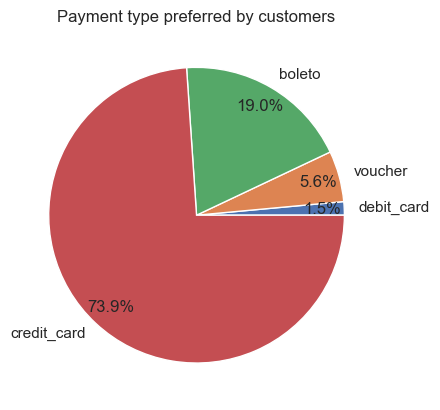

In [157]:
p_summ.plot(kind='pie',autopct='%1.1f%%',legend=False,pctdistance=0.85)
plt.title('Payment type preferred by customers')
plt.ylabel('')
plt.show()

### Customer segmentation based on revenue ###

In [158]:
order_cust_payments['revenue_segment']=np.where(order_cust_payments['payment_value']<=2000,'low',
         np.where(order_cust_payments['payment_value']<=8000,'medium','high'))

In [159]:
order_cust_payments.groupby('revenue_segment')['customer_unique_id'].count()

revenue_segment
high           1
low       103671
medium       214
Name: customer_unique_id, dtype: int64

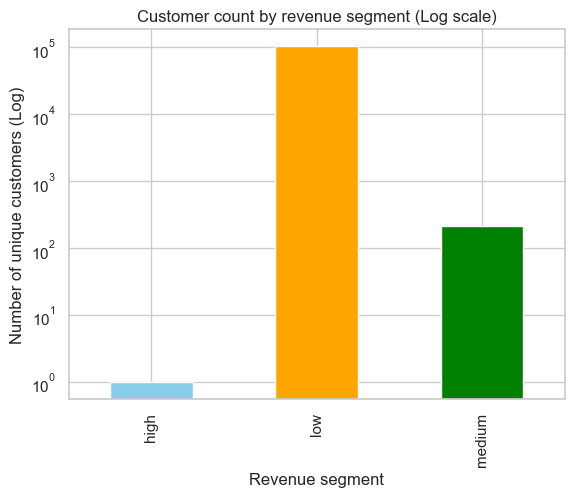

In [160]:
ax=order_cust_payments.groupby('revenue_segment')['customer_unique_id'].count().plot(kind='bar',color=['skyblue','orange','green'])
ax.set_yscale('log')
plt.title('Customer count by revenue segment (Log scale)')
plt.ylabel('Number of unique customers (Log)')
plt.xlabel('Revenue segment')
plt.show()

## Order level analysis ##

In [161]:
# Total orders placed

orders.shape[0]

99441

In [162]:
orders['month']=orders['order_purchase_timestamp'].dt.month_name()
orders['day_of_week']=orders['order_purchase_timestamp'].dt.day_name()
orders['weekend flag']=np.where(orders['day_of_week']=='Saturday','weekend',np.where(orders['day_of_week']=='Sunday','weekend','weekday'))

### Order status count ###

In [163]:
orders.groupby('order_status')['order_id'].count().reset_index(name='order_count')

,order_status,order_count
0,approved,2
1,canceled,625
2,created,5
3,delivered,96478
4,invoiced,314
5,processing,301
6,shipped,1107
7,unavailable,609


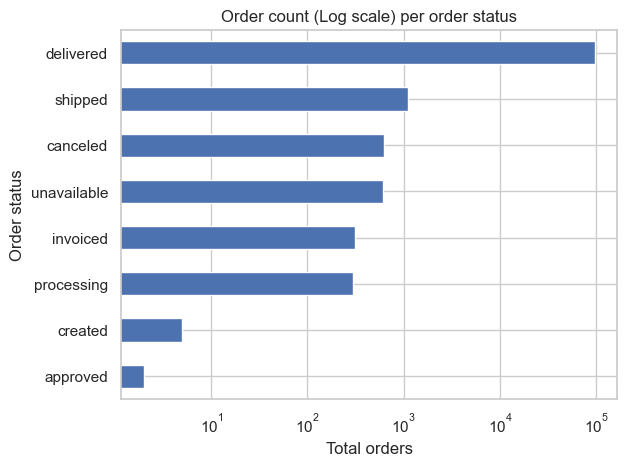

In [164]:
ax1=(orders.groupby('order_status')['order_id'].count().sort_values()).plot(kind='barh')
ax1.set_xscale('log')
plt.title('Order count (Log scale) per order status')
plt.ylabel('Order status')
plt.xlabel('Total orders')
plt.show()

In [165]:
orders_payments_clean=pd.merge(orders,order_payments,on='order_id',how='inner')
orders_payments_clean.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,date_inconsistency_flag,order_approval_hours,...,day_of_week,weekend flag,tot_orders,Total_installments,credit_card,boleto,voucher,debit_card,others,total_amount
0,a9fd47117c3f6b4e72456d5331e2bfb1,779609a1ecaee6f5ea1b6e50359c0aa1,delivered,2018-02-01 15:10:00,2018-02-01 15:34:00,2018-02-05 21:43:00,2018-02-14 22:36:00,2018-02-23,0,0.400000,...,Thursday,weekday,1,4,112.10,0.00,0.0,0.0,0.0,112.10
1,b62fb8675350e9d26562d21d74f310bc,196589770e3a1f3bec937543f965046b,delivered,2018-04-27 15:42:00,2018-05-01 05:32:00,2018-05-02 15:20:00,2018-05-08 19:44:00,2018-05-22,0,85.833333,...,Friday,weekday,1,1,0.00,61.69,0.0,0.0,0.0,61.69
2,3de92648437ce8d6e9d3b60f36cfa537,92ff4a1cd03e989698328acb4c3fc46c,delivered,2018-05-02 20:47:00,2018-05-02 21:18:00,2018-05-08 12:25:00,2018-05-14 16:19:00,2018-05-30,0,0.516667,...,Wednesday,weekday,1,1,174.97,0.00,0.0,0.0,0.0,174.97


### Month wise orders ###

In [166]:
orders_payments_clean.groupby('month')['order_id'].count().reset_index(name='total orders')

,month,total orders
0,April,9343
1,August,10843
2,December,5674
3,February,8508
4,January,8069
5,July,10318
6,June,9412
7,March,9893
8,May,10573
9,November,7544


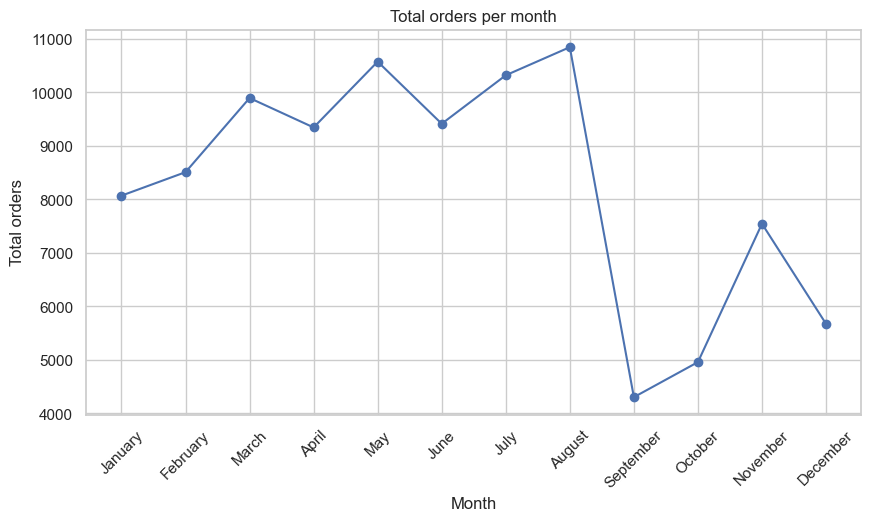

In [167]:
month_order=['January','February','March','April','May','June','July','August',
             'September','October','November','December']
orders_payments_clean['month']=pd.Categorical(orders_payments_clean['month'],categories=month_order,ordered=True)

ax2=orders_payments_clean.groupby('month',observed=False)['order_id'].count().plot(kind='line',marker='o',figsize=(10,5))
ax2.set_xticks(range(len(month_order)))
ax2.set_xticklabels(month_order,rotation=45)
plt.xlabel('Month')
plt.ylabel('Total orders')
plt.title('Total orders per month')
plt.show()

### Monthly revenue generated ###

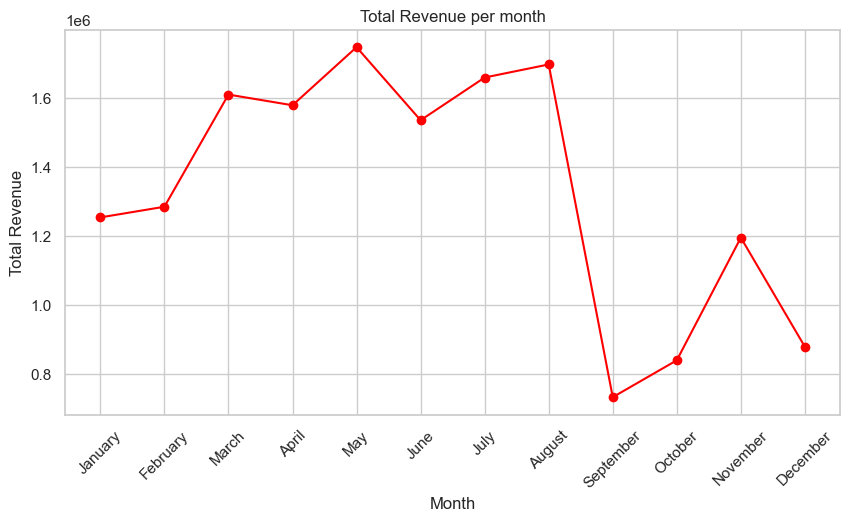

In [168]:
month_order=['January','February','March','April','May','June','July','August',
             'September','October','November','December']

ax3=orders_payments_clean.groupby('month',observed=False)['total_amount'].sum().plot(kind='line',marker='o',figsize=(10,5),color='red')
ax3.set_xticks(range(len(month_order)))
ax3.set_xticklabels(month_order,rotation=45)
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.title('Total Revenue per month')
plt.show()

### Total orders & Revenue per weekday/weekend flag ###

In [169]:
# Total orders

orders_payments_clean.groupby('weekend flag')['order_id'].count().reset_index(name='total orders')

,weekend flag,total orders
0,weekday,76593
1,weekend,22847


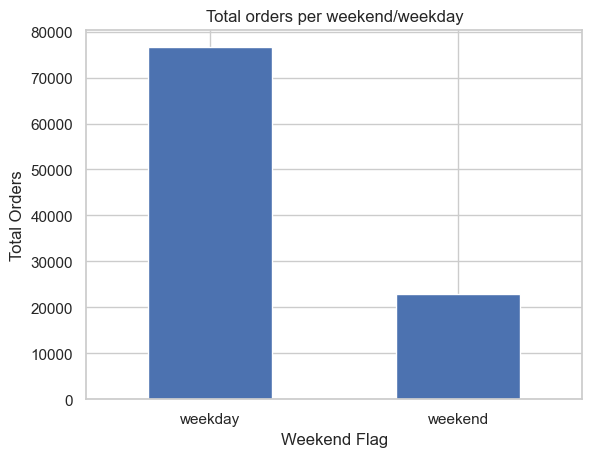

In [170]:
orders_payments_clean.groupby('weekend flag')['order_id'].count().plot(kind='bar')
plt.xlabel('Weekend Flag')
plt.ylabel('Total Orders')
plt.title('Total orders per weekend/weekday')
plt.xticks(rotation=0)
plt.show()

In [171]:
# Total revenue

orders_payments_clean.groupby('weekend flag')['total_amount'].sum().reset_index(name='total revenue')

,weekend flag,total revenue
0,weekday,12367988.08
1,weekend,3640884.04


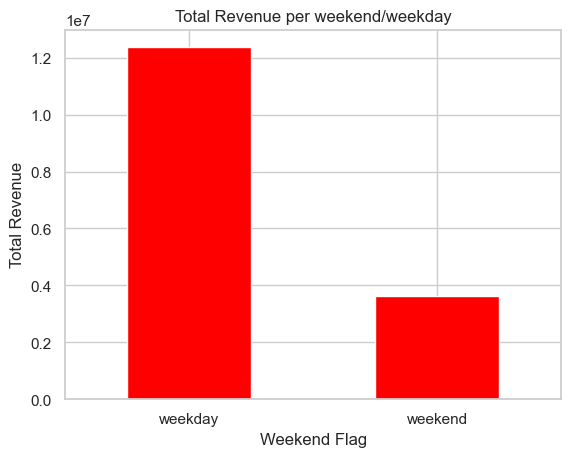

In [172]:
orders_payments_clean.groupby('weekend flag')['total_amount'].sum().plot(kind='bar',color='red')
plt.xlabel('Weekend Flag')
plt.ylabel('Total Revenue')
plt.title('Total Revenue per weekend/weekday')
plt.xticks(rotation=0)
plt.show()

In [173]:
# Total voucher amount

orders_payments_clean.voucher.sum()

np.float64(379436.87)

### Total orders per day of the week ###

In [174]:
orders_payments_clean.groupby('day_of_week')['order_id'].count().reset_index(name='total orders')

,day_of_week,total orders
0,Friday,14122
1,Monday,16196
2,Saturday,10887
3,Sunday,11960
4,Thursday,14760
5,Tuesday,15963
6,Wednesday,15552


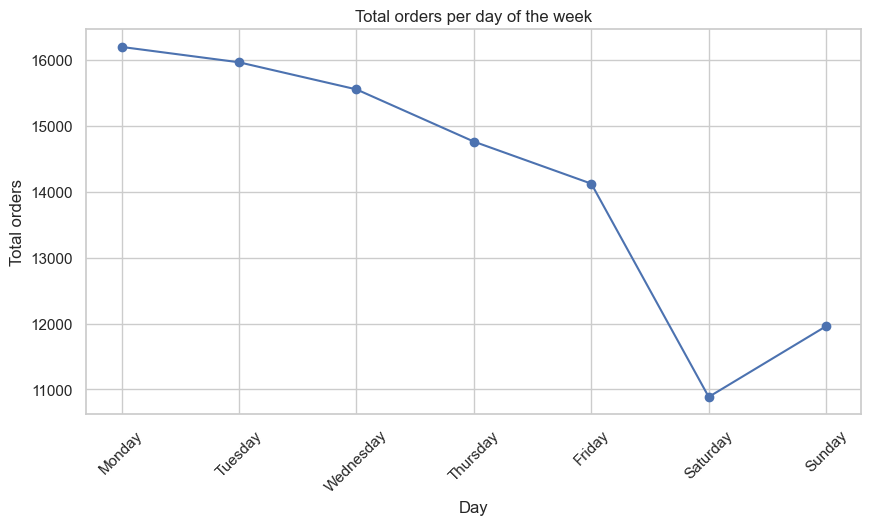

In [175]:
week_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
orders_payments_clean['day_of_week']=pd.Categorical(orders_payments_clean['day_of_week'],categories=week_order,ordered=True)

ax4=orders_payments_clean.groupby('day_of_week',observed=False)['order_id'].count().plot(kind='line',marker='o',figsize=(10,5))
ax4.set_xticks(range(len(week_order)))
ax4.set_xticklabels(week_order,rotation=45)
plt.xlabel('Day')
plt.ylabel('Total orders')
plt.title('Total orders per day of the week')
plt.show()

### Total revenue per day of the week ###

In [176]:
orders_payments_clean.groupby('day_of_week')['total_amount'].sum().reset_index(name='total revenue')

,day_of_week,total revenue
0,Monday,2622457.97
1,Tuesday,2560743.03
2,Wednesday,2493114.66
3,Thursday,2384544.22
4,Friday,2307128.20
5,Saturday,1768427.68
6,Sunday,1872456.36


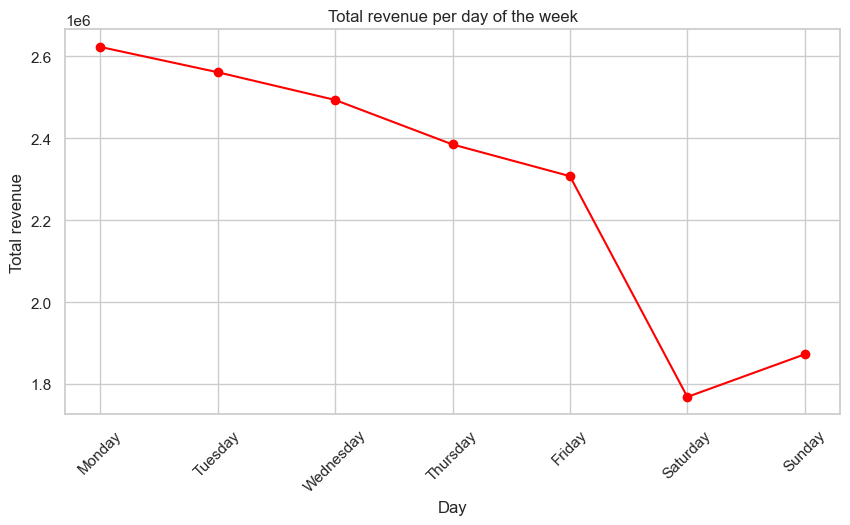

In [177]:
week_order=['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

ax5=orders_payments_clean.groupby('day_of_week',observed=False)['total_amount'].sum().plot(kind='line',marker='o',figsize=(10,5),color='red')
ax5.set_xticks(range(len(week_order)))
ax5.set_xticklabels(week_order,rotation=45)
plt.xlabel('Day')
plt.ylabel('Total revenue')
plt.title('Total revenue per day of the week')
plt.show()

In [178]:
# Median order approval hours for healthy records

orders_payments_clean.loc[orders_payments_clean['date_inconsistency_flag']==0,'order_approval_hours'].median()

0.3333333333333333

In [179]:
# Average order delivered time to carrier

orders_payments_clean.loc[orders_payments_clean['date_inconsistency_flag']==0,'carrier_delivered_days'].median()

1.0

In [180]:
# Average customer delivered time
orders_payments_clean.loc[orders_payments_clean['date_inconsistency_flag']==0,'customer_delivered_days'].median()

7.0

In [181]:
### Total orders per payment type

summ3=order_cust_payments.groupby('payment_type')['order_id'].nunique().sort_values().tail(4)
summ3.reset_index(name='total_orders')

,payment_type,total_orders
0,debit_card,1528
1,voucher,3866
2,boleto,19784
3,credit_card,76505


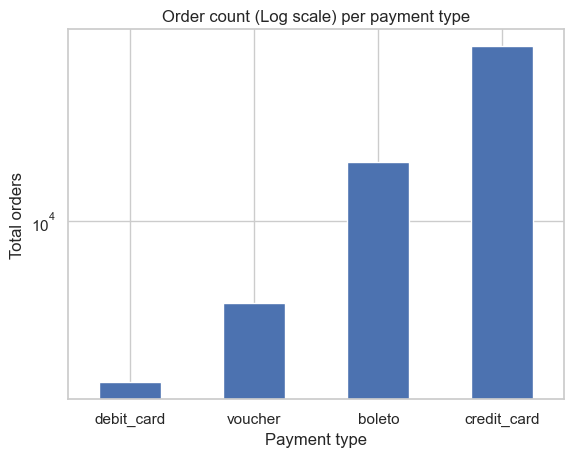

In [182]:
ax6=summ3.plot(kind='bar')
ax6.set_yscale('log')
plt.title('Order count (Log scale) per payment type')
plt.xlabel('Payment type')
plt.ylabel('Total orders')
plt.xticks(rotation=0)
plt.show()

### Timely delivered orders ###

In [183]:
orders_payments_clean.groupby('order_timely_delivered?')['order_id'].count().reset_index(name='total orders')

,order_timely_delivered?,total orders
0,No,10791
1,Yes,88649


### Hourly sales and revenue analysis ###

In [184]:
orders_payments_clean['hour']=orders_payments_clean['order_purchase_timestamp'].dt.hour

In [185]:
summ7=orders_payments_clean.groupby('hour')['order_id'].count().reset_index(name='total orders')
summ7['hour']=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]
summ7

,hour,total orders
0,0,2394
1,1,1170
2,2,510
3,3,272
4,4,206
5,5,188
6,6,502
7,7,1231
8,8,2967
9,9,4785


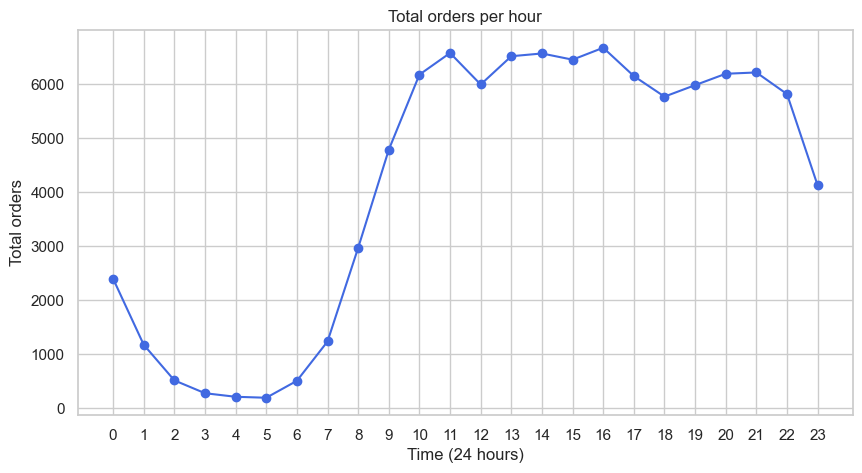

In [186]:
hour_order=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]

orders_payments_clean['hour']=pd.Categorical(orders_payments_clean['hour'],categories=hour_order,ordered=True)

ax7=orders_payments_clean.groupby('hour',observed=False)['order_id'].count().plot(kind='line',marker='o',figsize=(10,5),color='royalblue')
ax7.set_xticks(range(len(hour_order)))
ax7.set_xticklabels(hour_order,rotation=0)
plt.xlabel('Time (24 hours)')
plt.ylabel('Total orders')
plt.title('Total orders per hour')
plt.show()

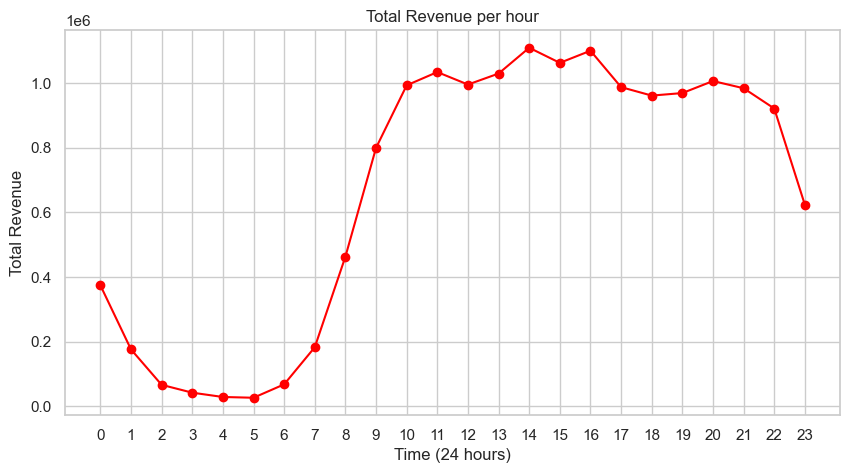

In [187]:
hour_order=[0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23]

ax8=orders_payments_clean.groupby('hour',observed=False)['total_amount'].sum().plot(kind='line',marker='o',figsize=(10,5),color='red')
ax8.set_xticks(range(len(hour_order)))
ax8.set_xticklabels(hour_order,rotation=0)
plt.xlabel('Time (24 hours)')
plt.ylabel('Total Revenue')
plt.title('Total Revenue per hour')
plt.show()

In [188]:
customer_orders=pd.merge(orders,customer,on='customer_id',how='inner')

In [189]:
customer_orders_geolocation=pd.merge(customer_orders,geolocation_new,left_on='customer_zip_code_prefix',right_on='geolocation_zip_code_prefix',how='left')
customer_orders_geolocation.head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,date_inconsistency_flag,order_approval_hours,...,weekend flag,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,a9fd47117c3f6b4e72456d5331e2bfb1,779609a1ecaee6f5ea1b6e50359c0aa1,delivered,2018-02-01 15:10:00,2018-02-01 15:34:00,2018-02-05 21:43:00,2018-02-14 22:36:00,2018-02-23,0,0.400000,...,weekday,abf1d6bd1161f2d55493942abb8c1402,14077,ribeirao preto,SP,14077.0,-21.121030,-47.781352,ribeirao preto,SP
1,b62fb8675350e9d26562d21d74f310bc,196589770e3a1f3bec937543f965046b,delivered,2018-04-27 15:42:00,2018-05-01 05:32:00,2018-05-02 15:20:00,2018-05-08 19:44:00,2018-05-22,0,85.833333,...,weekday,384ffc528dd30fd49eff3dda9f00ce86,13875,sao joao da boa vista,SP,13875.0,-21.983280,-46.777759,sao joao da boa vista,SP
2,3de92648437ce8d6e9d3b60f36cfa537,92ff4a1cd03e989698328acb4c3fc46c,delivered,2018-05-02 20:47:00,2018-05-02 21:18:00,2018-05-08 12:25:00,2018-05-14 16:19:00,2018-05-30,0,0.516667,...,weekday,daefb889f38f3b8b82e2b467a6a024e8,38015,uberaba,MG,38015.0,-19.747998,-47.926240,uberaba,MG


### Orders demographics analysis ###

In [190]:
# State wise order count

customer_orders_geolocation.groupby('geolocation_state')['order_id'].count().reset_index(name='total orders')

,geolocation_state,total orders
0,AC,81
1,AL,412
2,AM,148
3,AP,68
4,BA,3371
5,CE,1332
6,DF,1969
7,ES,2027
8,GO,2011
9,MA,743


### Total orders per state ###

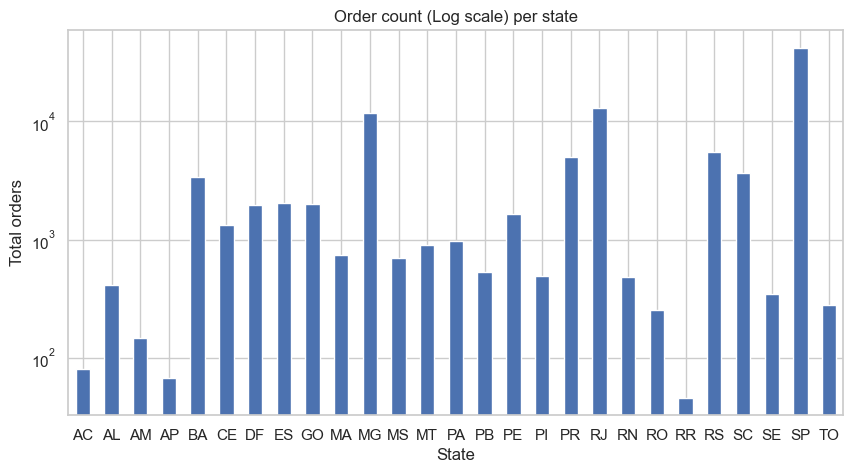

In [191]:
ax9=customer_orders_geolocation.groupby('geolocation_state')['order_id'].count().plot(kind='bar',figsize=(10,5))
ax9.set_yscale('log')
plt.title('Order count (Log scale) per state')
plt.xlabel('State')
plt.ylabel('Total orders')
plt.xticks(rotation=0)
plt.show()

### Total revenue per state ###

In [192]:
customer_orders_geolocation_payments=pd.merge(customer_orders_geolocation,order_payments,on='order_id',how='inner')

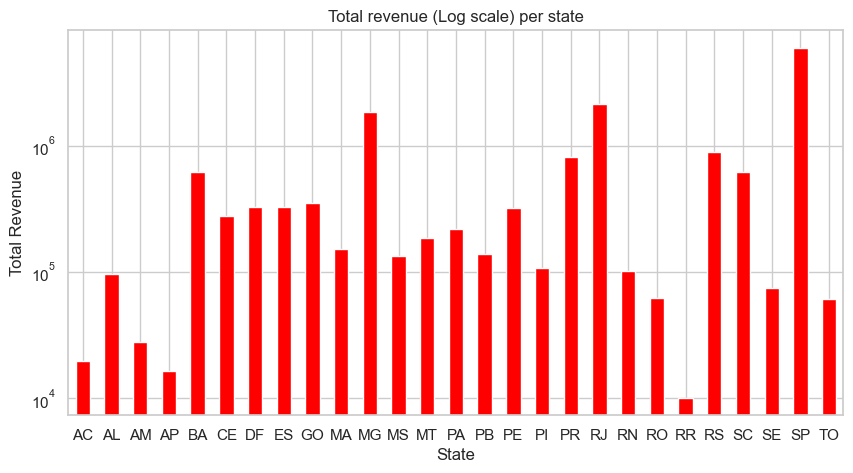

In [193]:
ax10=customer_orders_geolocation_payments.groupby('geolocation_state')['total_amount'].sum().plot(kind='bar',figsize=(10,5),color='red')
ax10.set_yscale('log')
plt.title('Total revenue (Log scale) per state')
plt.xlabel('State')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.show()

### State wise orders and revenue ###

In [194]:
customer_orders_geolocation_payments.groupby('geolocation_state')[['order_id','total_amount']].agg(total_orders=('order_id','count'),
                                                                                                   total_revenue=('total_amount','sum')).reset_index()

,geolocation_state,total_orders,total_revenue
0,AC,81,19680.62
1,AL,412,96780.44
2,AM,148,27966.93
3,AP,68,16262.80
4,BA,3371,615203.62
5,CE,1332,278311.31
6,DF,1969,326095.81
7,ES,2027,325490.67
8,GO,2011,349377.13
9,MA,743,151529.48


### City wise orders and revenue ###

In [195]:
customer_orders_geolocation_payments.groupby('geolocation_city')[['order_id','total_amount']].agg(total_orders=('order_id','count'),
                                                                                                   total_revenue=('total_amount','sum')).reset_index()

,geolocation_city,total_orders,total_revenue
0,abadia dos dourados,3,413.50
1,abadiania,1,1025.52
2,abaete,12,1946.81
3,abaetetuba,11,4672.27
4,abaiara,2,332.15
...,...,...,...
4043,xinguara,9,1608.51
4044,xique-xique,3,230.56
4045,zacarias,2,229.85
4046,ze doca,5,878.92


### Monthwise average delivery time ###

In [196]:
customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('month')['customer_delivered_days'].mean().reset_index(name='Average delivery time')

,month,Average delivery time
0,April,8.911832
1,August,5.951702
2,December,11.123434
3,February,12.104345
4,January,9.842443
5,July,6.724189
6,June,7.058442
7,March,11.639849
8,May,8.212614
9,November,10.585426


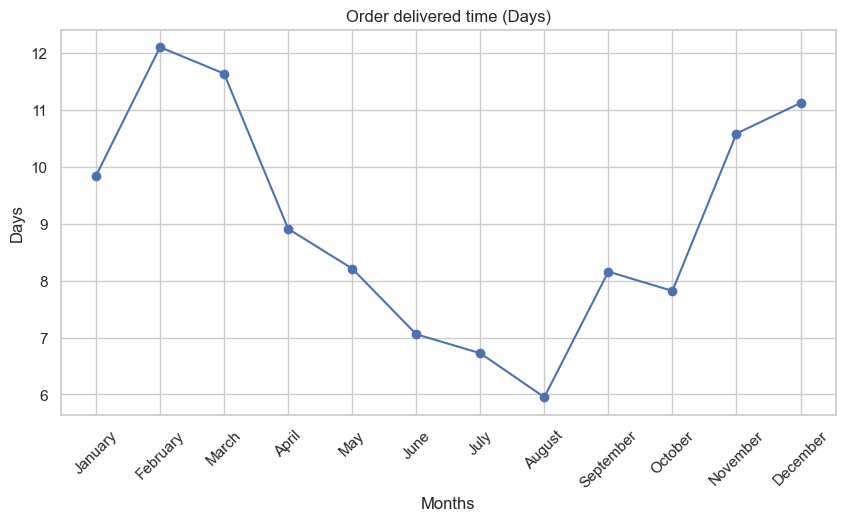

In [197]:
customer_orders_geolocation_payments['month']=pd.Categorical(customer_orders_geolocation_payments['month'],categories=month_order,ordered=True)

ax11=customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('month')['customer_delivered_days'].mean().plot(kind='line',marker='o',figsize=(10,5))
ax11.set_xticks(range(len(month_order)))
ax11.set_xticklabels(month_order,rotation=45)
plt.xlabel('Months')
plt.ylabel('Days')
plt.title('Order delivered time (Days)')
plt.show()

### Monthwise average carrier delivery time  ###

In [198]:
customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('month')['carrier_delivered_days'].mean().reset_index(name='Average carrier delivery time')

,month,Average carrier delivery time
0,January,2.690274
1,February,2.713373
2,March,2.459182
3,April,2.104846
4,May,1.894283
5,June,1.904089
6,July,2.139805
7,August,1.894158
8,September,2.283285
9,October,3.146082


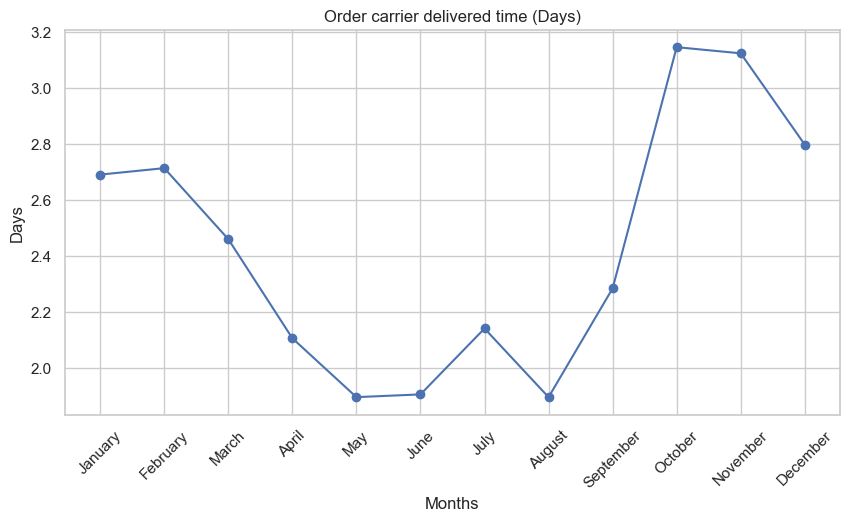

In [199]:
ax12=customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('month')['carrier_delivered_days'].mean().plot(kind='line',marker='o',figsize=(10,5))
ax12.set_xticks(range(len(month_order)))
ax12.set_xticklabels(month_order,rotation=45)
plt.xlabel('Months')
plt.ylabel('Days')
plt.title('Order carrier delivered time (Days)')
plt.show()

### Total orders per time period ###

In [200]:
customer_orders_geolocation_payments.groupby('order_purchase_period')['order_id'].count().reset_index(name='Total orders')

,order_purchase_period,Total orders
0,2016-09,3
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026


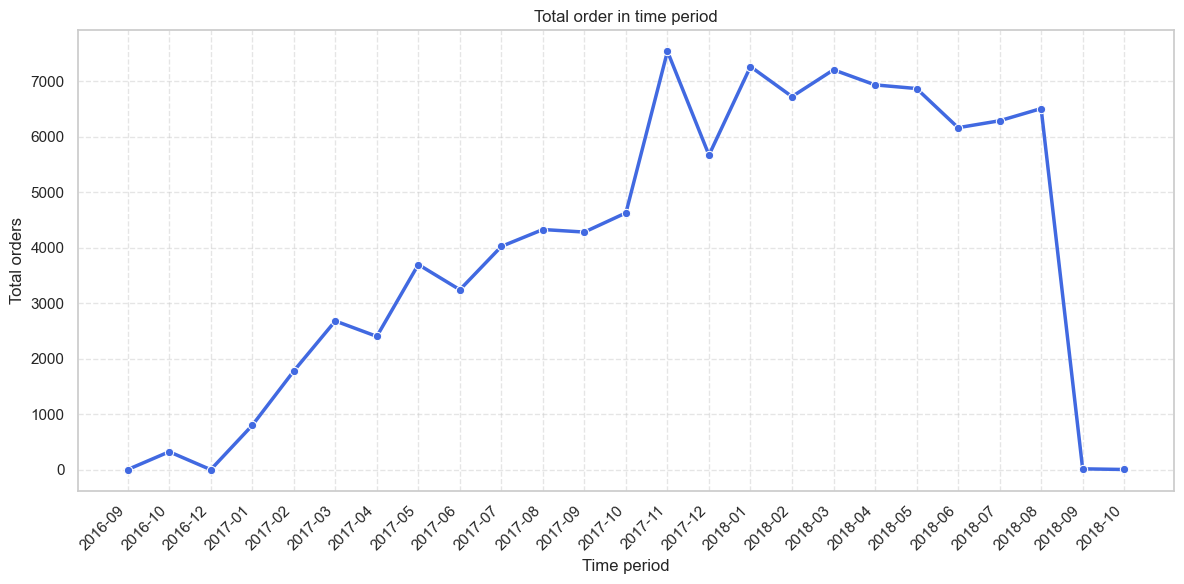

In [201]:
period_orders=customer_orders_geolocation_payments.groupby('order_purchase_period')['order_id'].count().reset_index(name='Total orders')

period_orders['order_purchase_period']=period_orders['order_purchase_period'].astype(str)

plt.figure(figsize=(12,6))
sns.set_theme(style='whitegrid')

sns.lineplot(data=period_orders,
             x='order_purchase_period',
             y='Total orders',
             marker='o',
             color='royalblue',
             linewidth=2.5,
             markersize=6)

plt.title('Total order in time period')
plt.xlabel('Time period')
plt.ylabel('Total orders')
plt.xticks(rotation=45,ha='right')
plt.grid(True,linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

In [202]:
period_revenue=customer_orders_geolocation_payments.groupby('order_purchase_period')['total_amount'].sum().reset_index(name='Total revenue')
period_revenue

,order_purchase_period,Total revenue
0,2016-09,252.24
1,2016-10,59090.48
2,2016-12,19.62
3,2017-01,138488.04
4,2017-02,291908.01
5,2017-03,449863.60
6,2017-04,417788.03
7,2017-05,592918.82
8,2017-06,511276.38
9,2017-07,592382.92


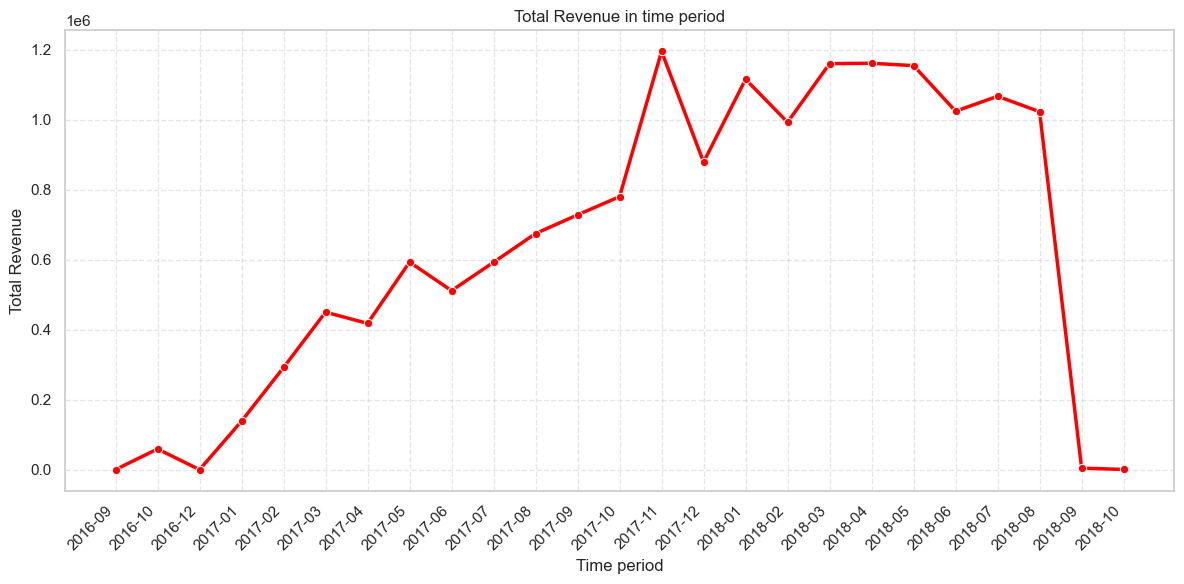

In [203]:
period_revenue['order_purchase_period']=period_revenue['order_purchase_period'].astype(str)

plt.figure(figsize=(12,6))
sns.set_theme(style='whitegrid')

sns.lineplot(data=period_revenue,
             x='order_purchase_period',
             y='Total revenue',
             marker='o',
             color='red',
             linewidth=2.5,
             markersize=6)

plt.title('Total Revenue in time period')
plt.xlabel('Time period')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45,ha='right')
plt.grid(True,linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

### Average delivery days per state and city ###

In [204]:
customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('geolocation_state')['customer_delivered_days'].mean().reset_index(name='Delivery days')

,geolocation_state,Delivery days
0,AC,17.233766
1,AL,20.454082
2,AM,23.090278
3,AP,23.223881
4,BA,15.583073
5,CE,17.598726
6,DF,9.377589
7,ES,11.946483
8,GO,12.016736
9,MA,17.542735


In [205]:
customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('geolocation_city')['customer_delivered_days'].mean().reset_index(name='Delivery days')

,geolocation_city,Delivery days
0,abadia dos dourados,10.500000
1,abadiania,21.000000
2,abaete,7.500000
3,abaetetuba,21.454545
4,abaiara,31.500000
...,...,...
4024,xinguara,31.875000
4025,xique-xique,11.333333
4026,zacarias,10.500000
4027,ze doca,24.600000


In [206]:
time_delivery_days=customer_orders_geolocation_payments.loc[customer_orders_geolocation_payments['date_inconsistency_flag']==0].groupby('order_purchase_period')['customer_delivered_days'].mean().reset_index(name='Delivery days')
time_delivery_days

,order_purchase_period,Delivery days
0,2016-09,NaN
1,2016-10,5.635338
2,2016-12,1.000000
3,2017-01,8.763685
4,2017-02,9.098182
5,2017-03,9.404322
6,2017-04,10.749013
7,2017-05,7.869972
8,2017-06,8.433866
9,2017-07,8.060922


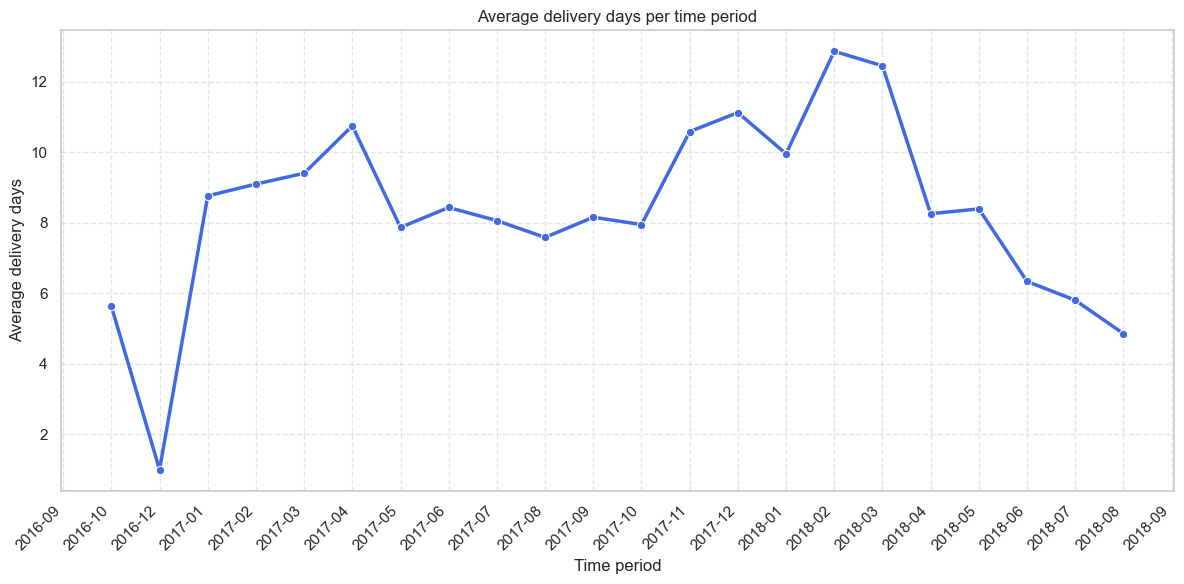

In [207]:
time_delivery_days['order_purchase_period']=time_delivery_days['order_purchase_period'].astype(str)

plt.figure(figsize=(12,6))
sns.set_theme(style='whitegrid')

sns.lineplot(data=time_delivery_days,
             x='order_purchase_period',
             y='Delivery days',
             marker='o',
             color='royalblue',
             linewidth=2.5,
             markersize=6)

plt.title('Average delivery days per time period')
plt.xlabel('Time period')
plt.ylabel('Average delivery days')
plt.xticks(rotation=45,ha='right')
plt.grid(True,linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

## Products level analysis ##

### Order items & Products ###

In [208]:
df2_temp=pd.merge(order_items,products,on='product_id',how='inner')

In [209]:
order_items_products=pd.merge(df2_temp,product_category,on='product_category_name',how='left')

In [210]:
order_items_products_sellers=pd.merge(order_items_products,sellers,on='seller_id',how='inner')
order_items_products_sellers

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.900002,13.290000,cool_stuff,4,650.0,28.0,9.0,14.0,cool_stuff,27277,volta redonda,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.899994,19.930000,pet_shop,2,30000.0,50.0,30.0,40.0,pet_shop,3471,sao paulo,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.000000,17.870001,moveis_decoracao,2,3050.0,33.0,13.0,33.0,furniture_decor,37564,borda da mata,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:00,12.990000,12.790000,perfumaria,1,200.0,16.0,10.0,15.0,perfumery,14403,franca,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:00,199.899994,18.139999,ferramentas_jardim,1,3750.0,35.0,40.0,30.0,garden_tools,87900,loanda,PR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:00,299.989990,43.410000,utilidades_domesticas,3,10150.0,89.0,15.0,40.0,housewares,88303,itajai,SC
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:00,350.000000,36.529999,informatica_acessorios,1,8950.0,45.0,26.0,38.0,computers_accessories,1206,sao paulo,SP
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:00,99.900002,16.950001,esporte_lazer,1,967.0,21.0,24.0,19.0,sports_leisure,80610,curitiba,PR
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:00,55.990002,8.720000,informatica_acessorios,1,100.0,20.0,20.0,20.0,computers_accessories,4733,sao paulo,SP


### Total products per category ###

In [211]:
order_items_products_sellers.groupby('product_category_name_english')['order_id'].count().reset_index(name='total orders').sort_values('total orders',ascending=False)

,product_category_name_english,total orders
7,bed_bath_table,12718
43,health_beauty,9670
65,sports_leisure,8641
39,furniture_decor,8334
15,computers_accessories,7827
...,...,...
3,arts_and_craftmanship,24
52,la_cuisine,14
11,cds_dvds_musicals,14
29,fashion_childrens_clothes,8


### Top 10 products categories by order count ###

In [212]:
psumm1=order_items_products_sellers.groupby('product_category_name_english')['order_id'].count()\
    .reset_index(name='total orders').sort_values('total orders',ascending=False).head(10)
psumm1

,product_category_name_english,total orders
7,bed_bath_table,12718
43,health_beauty,9670
65,sports_leisure,8641
39,furniture_decor,8334
15,computers_accessories,7827
49,housewares,6964
70,watches_gifts,5991
68,telephony,4545
42,garden_tools,4347
5,auto,4235


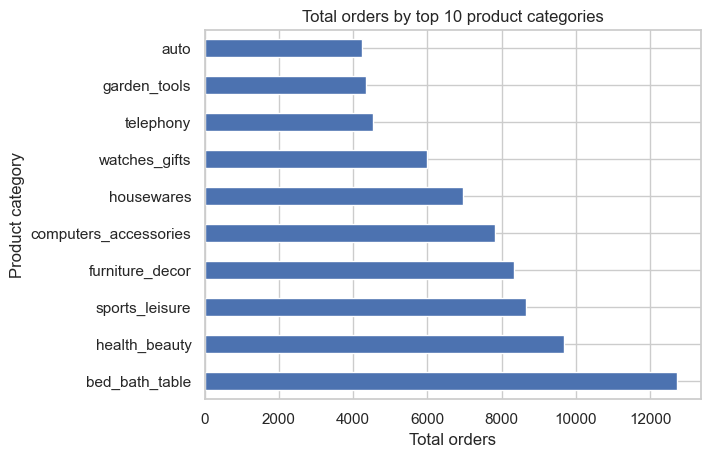

In [213]:
psumm1.plot(kind='barh',x='product_category_name_english',y='total orders',legend=False)
plt.title('Total orders by top 10 product categories')
plt.xlabel('Total orders')
plt.ylabel('Product category')
plt.show()

### Total products per product category ###

In [214]:
order_items_products_sellers.groupby('product_category_name_english')['product_id'].count().reset_index(name='total products')

,product_category_name_english,total products
0,agro_industry_and_commerce,212
1,air_conditioning,297
2,art,209
3,arts_and_craftmanship,24
4,audio,364
...,...,...
66,stationery,2517
67,tablets_printing_image,83
68,telephony,4545
69,toys,4117


In [215]:
psumm2=order_items_products_sellers.groupby('product_category_name_english')['product_id'].count()\
    .reset_index(name='total products').sort_values('total products',ascending=False).head(10)
psumm2

,product_category_name_english,total products
7,bed_bath_table,12718
43,health_beauty,9670
65,sports_leisure,8641
39,furniture_decor,8334
15,computers_accessories,7827
49,housewares,6964
70,watches_gifts,5991
68,telephony,4545
42,garden_tools,4347
5,auto,4235


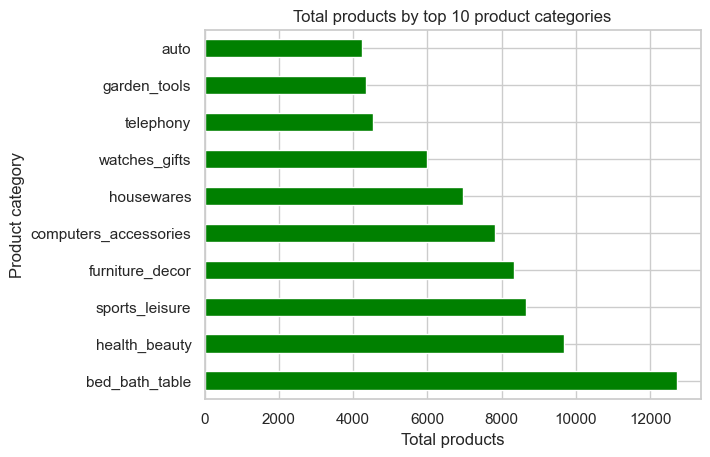

In [216]:
psumm2.plot(kind='barh',x='product_category_name_english',y='total products',color='green',legend=False)
plt.title('Total products by top 10 product categories')
plt.xlabel('Total products')
plt.ylabel('Product category')
plt.show()

In [217]:
tmp_df=pd.merge(order_items_products_sellers,order_payments,on='order_id',how='inner')

### Total orders & Revenue per product category ###

In [218]:
tmp_df.groupby('product_category_name_english')[['order_id','total_amount']].agg(total_orders=('order_id','count'),
                                                                                 total_revenue=('total_amount','sum')).reset_index()

,product_category_name_english,total_orders,total_revenue
0,agro_industry_and_commerce,212,118730.61
1,air_conditioning,297,91170.66
2,art,209,30992.93
3,arts_and_craftmanship,24,2326.17
4,audio,364,60324.62
...,...,...,...
66,stationery,2517,317440.07
67,tablets_printing_image,83,10042.93
68,telephony,4545,486882.05
69,toys,4117,619037.69


### Total products per category ###

In [219]:
(tmp_df.groupby('product_category_name_english')['product_id'].count()).sort_values(ascending=False).reset_index(name='total products')

,product_category_name_english,total products
0,bed_bath_table,12718
1,health_beauty,9667
2,sports_leisure,8641
3,furniture_decor,8334
4,computers_accessories,7827
...,...,...
66,arts_and_craftmanship,24
67,la_cuisine,14
68,cds_dvds_musicals,14
69,fashion_childrens_clothes,8


### Average freight value ###

In [258]:
tmp_df.groupby('product_category_name_english')['freight_value'].mean().reset_index(name='Average freight value').sort_values('Average freight value', ascending= False)

,product_category_name_english,Average freight value
14,computers,48.454680
45,home_appliances_2,44.538571
41,furniture_mattress_and_upholstery,42.906841
51,kitchen_dining_laundry_garden_furniture,42.702598
38,furniture_bedroom,42.497523
...,...,...
36,food,14.256922
46,home_comfort_2,13.677000
27,fashio_female_clothing,12.953125
9,books_imported,12.830833


In [221]:
tmp_df.groupby('product_category_name_english')['product_weight_g'].mean().reset_index(name='Average weight')

,product_category_name_english,Average weight
0,agro_industry_and_commerce,3625.113208
1,air_conditioning,4118.016835
2,art,1557.545455
3,arts_and_craftmanship,1369.875000
4,audio,1218.423077
...,...,...
66,stationery,2751.514899
67,tablets_printing_image,307.096386
68,telephony,261.622222
69,toys,1857.368472


### Average price & Freight value per product category ###

In [222]:
order_items_products_sellers.groupby('product_category_name_english')[['price','freight_value']].sum().reset_index()

,product_category_name_english,price,freight_value
0,agro_industry_and_commerce,7.253047e+04,5843.600017
1,air_conditioning,5.502496e+04,6749.229999
2,art,2.420264e+04,4045.170012
3,arts_and_craftmanship,1.814010e+03,370.129998
4,audio,5.068850e+04,5710.439979
...,...,...,...
66,stationery,2.309432e+05,46798.480058
67,tablets_printing_image,7.528410e+03,1226.199994
68,telephony,3.236675e+05,71215.790354
69,toys,4.839466e+05,77425.950112


### State wise popular categories based on order count ###

In [223]:
order_items_products_sellers.groupby(['seller_state','product_category_name_english'])['order_id'].count().reset_index(name='Total orders').sort_values('seller_state')

,seller_state,product_category_name_english,Total orders
0,AC,books_technical,1
1,AM,telephony,3
2,BA,baby,5
3,BA,computers,154
4,BA,computers_accessories,42
...,...,...,...
497,SP,stationery,1951
498,SP,tablets_printing_image,82
499,SP,telephony,3913
500,SP,toys,2859


In [224]:
order_items_products_sellers.price.sum()

np.float64(13591643.701720357)

In [225]:
order_items_products_sellers.freight_value.sum()

np.float64(2251909.5430001207)

## Product category penetration ##

In [226]:
total_orders=order_items_products_sellers['order_id'].nunique()

category_penetration=order_items_products_sellers.groupby('product_category_name_english')\
['order_id'].nunique().reset_index(name='unique_orders')

category_penetration['penetration_percentage']=(category_penetration['unique_orders']/total_orders)*100

category_penetration=category_penetration.sort_values(by='penetration_percentage',ascending=False).reset_index(drop=True)
category_penetration.head(10)

,product_category_name_english,unique_orders,penetration_percentage
0,bed_bath_table,10860,11.006831
1,health_beauty,8836,8.955466
2,sports_leisure,7720,7.824377
3,computers_accessories,6689,6.779438
4,furniture_decor,6449,6.536193
5,housewares,5884,5.963554
6,watches_gifts,5624,5.700039
7,telephony,4199,4.255772
8,auto,3897,3.949689
9,toys,3886,3.938540


In [227]:
category_penetration.to_csv(r"C:\Users\HP Victus\Desktop\temp power bi olist\category_penetration.csv")

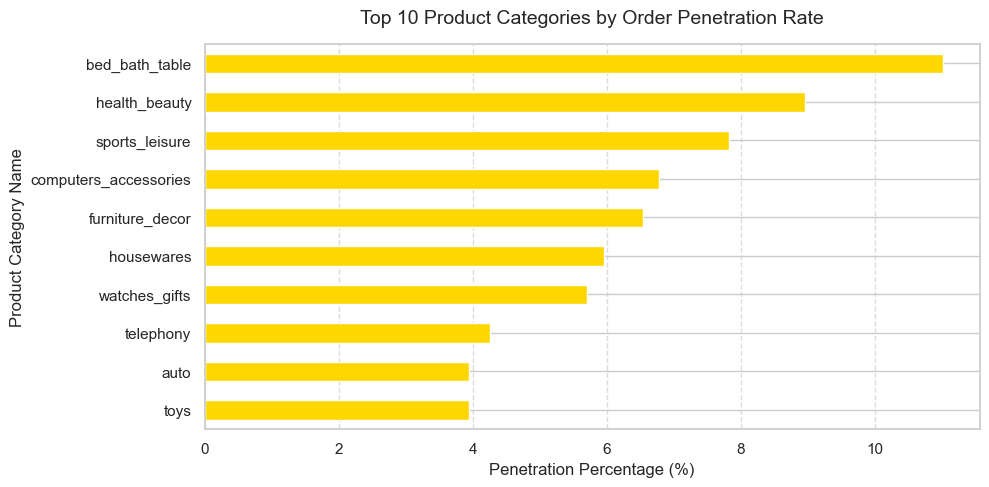

In [228]:
top_categories = category_penetration.sort_values(
    by='penetration_percentage', ascending=True
).tail(10)

# 2. Plot as a horizontal bar chart
ax = top_categories.plot(
    kind='barh',
    x='product_category_name_english',
    y='penetration_percentage',
    figsize=(10, 5),
    color='gold',
    legend=False,
)

# 3. Customize titles and labels
plt.title(
    'Top 10 Product Categories by Order Penetration Rate',
    fontsize=14,
    pad=15,
)
plt.xlabel('Penetration Percentage (%)', fontsize=12)
plt.ylabel('Product Category Name', fontsize=12)

# Add gridlines for easier reading
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

### Pareto analysis ###

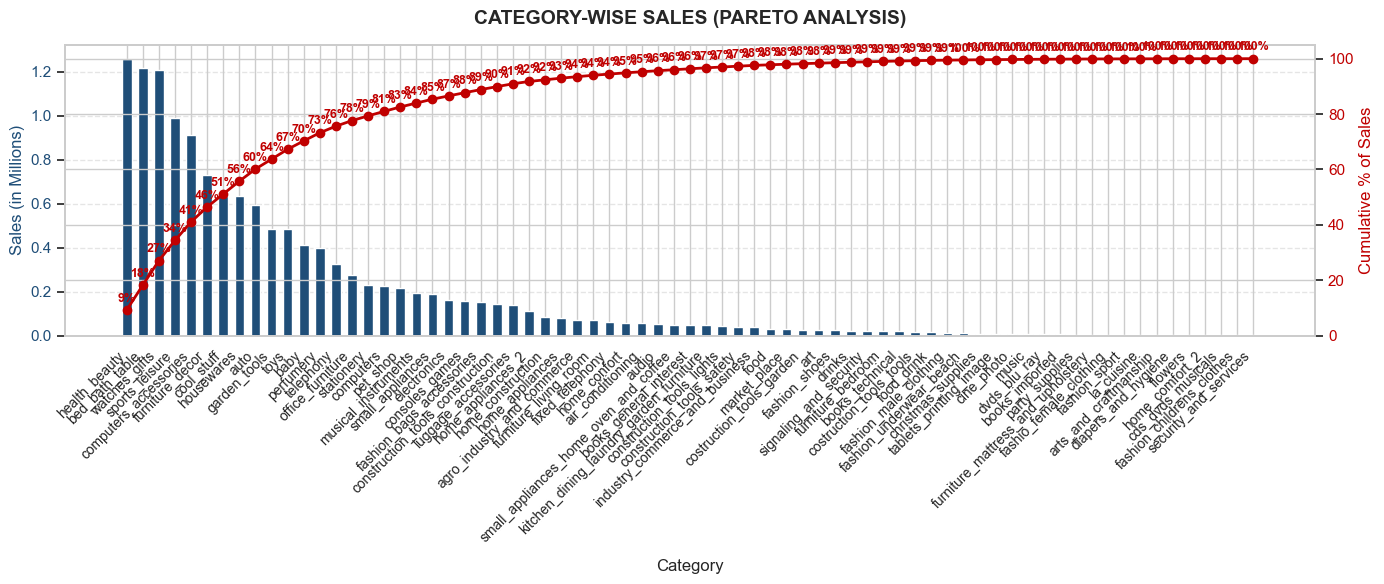

In [229]:

pareto_df = (
    order_items_products_sellers.groupby('product_category_name_english')[
        'price'
    ]
    .sum()
    .reset_index(name='sales')
    .sort_values(by='sales', ascending=False)
    .reset_index(drop=True)
)

# 2. Calculate cumulative percentage
pareto_df['cumulative_sales'] = pareto_df['sales'].cumsum()
total_sales = pareto_df['sales'].sum()
pareto_df['cumulative_percentage'] = (
    pareto_df['cumulative_sales'] / total_sales
) * 100

fig, ax1 = plt.subplots(figsize=(14, 6))


ax1.bar(
    pareto_df['product_category_name_english'],
    pareto_df['sales'] / 1e6,
    color='#1f4e78',
    width=0.6,
    label='Sales',
)
ax1.set_xlabel('Category', fontsize=12, labelpad=10)
ax1.set_ylabel('Sales (in Millions)', color='#1f4e78', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#1f4e78')
plt.xticks(rotation=45, ha='right', fontsize=10)


ax2 = ax1.twinx()
ax2.plot(
    pareto_df['product_category_name_english'],
    pareto_df['cumulative_percentage'],
    color='#c00000',
    marker='o',
    linewidth=2,
    label='Cumulative % of Sales',
)
ax2.set_ylabel('Cumulative % of Sales', color='#c00000', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#c00000')
ax2.set_ylim(0, 105)

# 4. Add data labels above the cumulative percentage points
for i, txt in enumerate(pareto_df['cumulative_percentage']):
  ax2.annotate(
      f'{int(round(txt))}%',
      (pareto_df['product_category_name_english'][i], txt + 3),
      ha='center',
      fontsize=9,
      color='#c00000',
      weight='bold',
  )

plt.title(
    'CATEGORY-WISE SALES (PARETO ANALYSIS)',
    fontsize=14,
    weight='bold',
    pad=15,
)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

### Relationship between price and freight value per product  ###

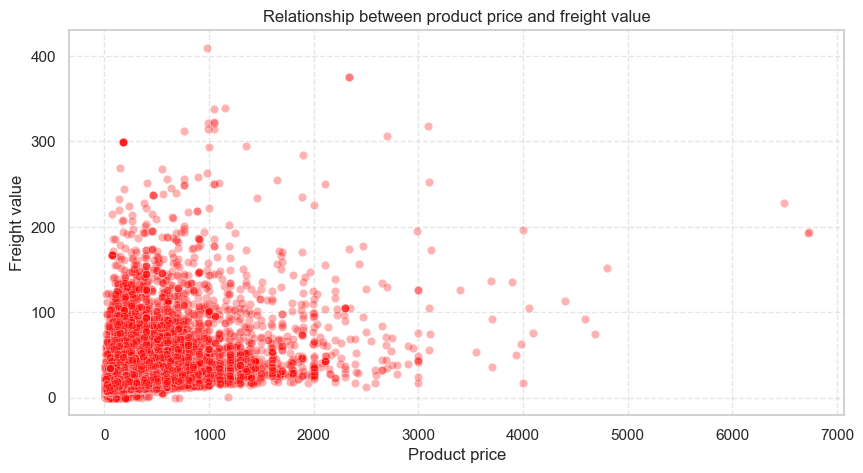

In [230]:
plt.figure(figsize=(10,5))

sns.scatterplot(data=order_items_products_sellers,x='price',y='freight_value',alpha=0.3,color='red')

plt.title('Relationship between product price and freight value')
plt.xlabel('Product price')
plt.ylabel('Freight value')
plt.grid(True,linestyle='--',alpha=0.5)
plt.show()

In [231]:
correlation=order_items_products_sellers[['price','freight_value']].corr()
print(correlation)

                  price  freight_value
price          1.000000       0.414204
freight_value  0.414204       1.000000


### Cross selling products ###

In [232]:
multi_item_orders = order_items_products_sellers.groupby('order_id').filter(
    lambda x: len(x) > 1)

basket = pd.crosstab(
    multi_item_orders['order_id'],
    multi_item_orders['product_category_name_english'],)

basket_sets = basket.map(lambda x: 1 if x > 0 else 0)

co_occurrence_matrix = basket_sets.T.dot(basket_sets)

target_category = 'bed_bath_table'
print(
    f'Top categories bought with {target_category}:\n',
    co_occurrence_matrix[target_category]
    .sort_values(ascending=False)
    .head(6),)

Top categories bought with bed_bath_table:
 product_category_name_english
bed_bath_table     1610
furniture_decor      73
home_confort         43
housewares           34
baby                 17
health_beauty        13
Name: bed_bath_table, dtype: int64


In [233]:
pd.DataFrame(co_occurrence_matrix[target_category]
    .sort_values(ascending=False)
    .head(6),).reset_index()

,product_category_name_english,bed_bath_table
0,bed_bath_table,1610
1,furniture_decor,73
2,home_confort,43
3,housewares,34
4,baby,17
5,health_beauty,13


### Seller level analysis ###

### Total sellers per state ###

In [234]:
order_items_products_sellers.groupby('seller_state')['seller_id'].count().reset_index()

,seller_state,seller_id
0,AC,1
1,AM,3
2,BA,643
3,CE,94
4,DF,899
5,ES,372
6,GO,520
7,MA,405
8,MG,8827
9,MS,50


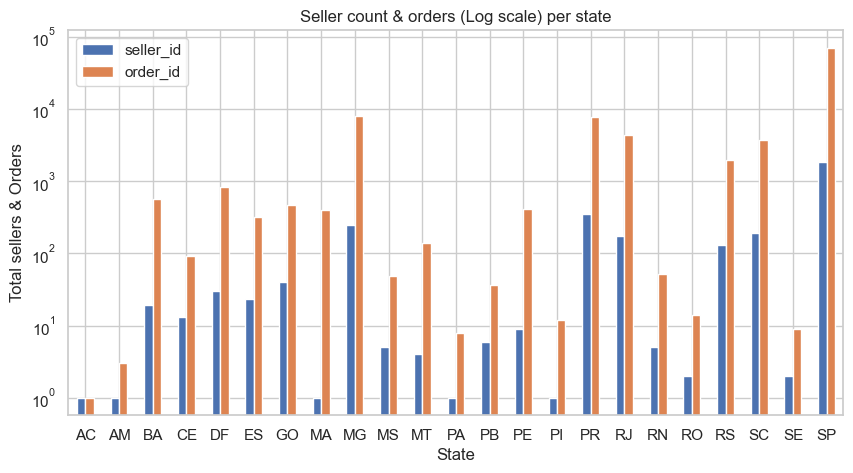

In [235]:
ax14=order_items_products_sellers.groupby('seller_state')[['seller_id','order_id']].nunique().plot(kind='bar',figsize=(10,5))
ax14.set_yscale('log')
plt.title('Seller count & orders (Log scale) per state')
plt.xlabel('State')
plt.ylabel('Total sellers & Orders')
plt.xticks(rotation=0)
plt.show()

In [236]:
order_items_products_sellers_orders=pd.merge(order_items_products_sellers,orders,on='order_id',how='inner')
order_items_products_sellers_orders

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_photos_qty,product_weight_g,...,order_estimated_delivery_date,date_inconsistency_flag,order_approval_hours,carrier_delivered_days,customer_delivered_days,order_timely_delivered?,order_purchase_period,month,day_of_week,weekend flag
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:00,58.900002,13.290000,cool_stuff,4,650.0,...,2017-09-29,0,0.766667,6.0,1.0,Yes,2017-09,September,Wednesday,weekday
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:00,239.899994,19.930000,pet_shop,2,30000.0,...,2017-05-15,0,0.200000,8.0,8.0,Yes,2017-04,April,Wednesday,weekday
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:00,199.000000,17.870001,moveis_decoracao,2,3050.0,...,2018-02-05,0,0.250000,1.0,6.0,Yes,2018-01,January,Sunday,weekend
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:00,12.990000,12.790000,perfumaria,1,200.0,...,2018-08-20,0,0.166667,2.0,4.0,Yes,2018-08,August,Wednesday,weekday
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:00,199.899994,18.139999,ferramentas_jardim,1,3750.0,...,2017-03-17,0,0.216667,11.0,13.0,Yes,2017-02,February,Saturday,weekend
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112645,fffc94f6ce00a00581880bf54a75a037,1,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-05-02 04:11:00,299.989990,43.410000,utilidades_domesticas,3,10150.0,...,2018-05-18,0,38.233333,0.0,15.0,Yes,2018-04,April,Monday,weekday
112646,fffcd46ef2263f404302a634eb57f7eb,1,32e07fd915822b0765e448c4dd74c828,f3c38ab652836d21de61fb8314b69182,2018-07-20 04:31:00,350.000000,36.529999,informatica_acessorios,1,8950.0,...,2018-08-01,0,66.083333,0.0,6.0,Yes,2018-07,July,Saturday,weekend
112647,fffce4705a9662cd70adb13d4a31832d,1,72a30483855e2eafc67aee5dc2560482,c3cfdc648177fdbbbb35635a37472c53,2017-10-30 17:14:00,99.900002,16.950001,esporte_lazer,1,967.0,...,2017-11-10,0,24.116667,1.0,1.0,Yes,2017-10,October,Monday,weekday
112648,fffe18544ffabc95dfada21779c9644f,1,9c422a519119dcad7575db5af1ba540e,2b3e4a2a3ea8e01938cabda2a3e5cc79,2017-08-21 00:04:00,55.990002,8.720000,informatica_acessorios,1,100.0,...,2017-08-25,0,1.033333,0.0,1.0,Yes,2017-08,August,Monday,weekday


In [237]:
order_items_products_sellers_orders.to_csv(r"C:\Users\HP Victus\Desktop\temp power bi olist\order_items_products_sellers_orders.csv")

### Delivery days per seller ###

In [238]:
ssumm1=order_items_products_sellers_orders.loc[order_items_products_sellers_orders['date_inconsistency_flag']==0]\
.groupby('seller_id')['customer_delivered_days'].mean().reset_index(name='Average delivery time').sort_values('Average delivery time',ascending=False)\
.head(10)
ssumm1

,seller_id,Average delivery time
2688,df683dfda87bf71ac3fc63063fba369d,186.000000
953,4fb41dff7c50136976d1a5cf004a42e2,63.333333
1734,8e29d051f810eb22959ede205b462b9f,58.000000
2873,eebb3372362aa9a46975164bed19a7e7,44.250000
587,327b89b872c14d1c0be7235ef4871685,44.000000
1954,a154d7316f158bb42e6fa18bbe3afd3a,42.500000
2282,be1e9e378700cecaa4ebf71433d7915c,42.500000
2842,ebef8d8c92b4fd3226e5d407bbff21ac,38.333333
388,20d53aad4fe5ee93a64f8839609d3586,37.000000
789,427165bf50f8ca07efc7bdc2bfcf1688,36.800000


<Axes: ylabel='seller_id'>

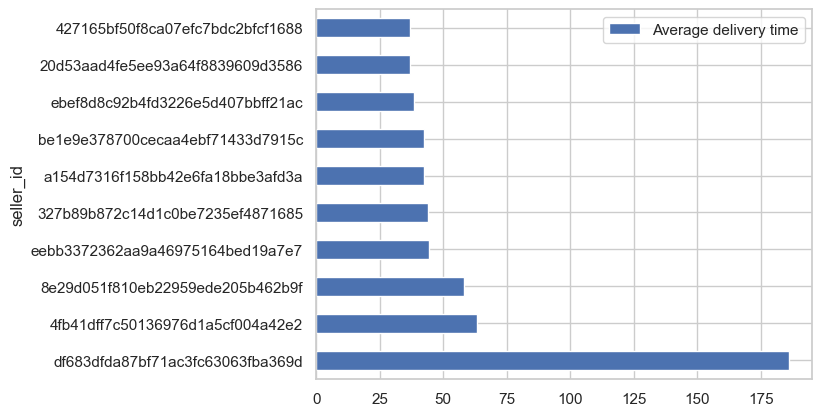

In [239]:
ssumm1.plot(kind='barh',y='Average delivery time',x='seller_id')

### Seller product diversity ###

In [240]:
seller_diversity = (
    order_items_products_sellers.groupby('seller_id')
    .agg(
        unique_categories=('product_category_name_english', 'nunique'),
        unique_products=('product_id', 'nunique'),
        total_items_sold=('order_item_id', 'count'),)
    .sort_values(by='unique_categories', ascending=False)
    .reset_index())

seller_diversity.head(10)

,seller_id,unique_categories,unique_products,total_items_sold
0,b2ba3715d723d245138f291a6fe42594,27,183,363
1,4e922959ae960d389249c378d1c939f5,24,136,454
2,955fee9216a65b617aa5c0531780ce60,23,104,1499
3,1da3aeb70d7989d1e6d9b0e887f97c23,21,155,328
4,f8db351d8c4c4c22c6835c19a46f01b0,20,146,724
5,18a349e75d307f4b4cc646a691ed4216,17,42,148
6,6edacfd9f9074789dad6d62ba7950b9c,15,144,219
7,70a12e78e608ac31179aea7f8422044b,15,121,328
8,44073f8b7e41514de3b7815dd0237f4f,15,77,153
9,8b28d096634035667e8263d57ba3368c,14,49,155


In [262]:
seller_diversity.to_csv(r"C:\Users\HP Victus\Desktop\temp power bi olist\seller_diversity.csv")

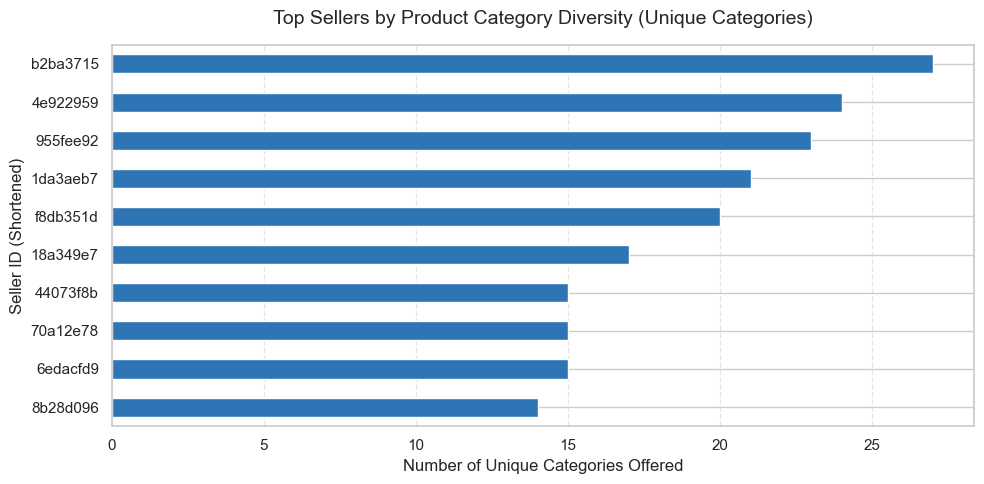

In [241]:
top_diverse = seller_diversity.sort_values(by='unique_categories', ascending=True).tail(10)

top_diverse['short_seller_id'] = top_diverse['seller_id'].str[:8]

ax = top_diverse.plot(kind='barh',x='short_seller_id',y='unique_categories',figsize=(10, 5),color='#2e75b6',legend=False,)

plt.title('Top Sellers by Product Category Diversity (Unique Categories)',fontsize=14,pad=15,)
plt.xlabel('Number of Unique Categories Offered', fontsize=12)
plt.ylabel('Seller ID (Shortened)', fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Seller demographics and delivery performance ###

In [242]:
seller_geo_performance = (order_items_products_sellers_orders.loc[order_items_products_sellers_orders['date_inconsistency_flag']==0].groupby('seller_state').agg(
        avg_delivery_time=('customer_delivered_days','mean'),
        median_delivery_time=('customer_delivered_days','median'),
        total_orders=('order_id','nunique'),
        total_items_sold=('order_item_id','count'),).sort_values(by='avg_delivery_time', ascending=False).reset_index())
seller_geo_performance.head(10)

,seller_state,avg_delivery_time,median_delivery_time,total_orders,total_items_sold
0,AM,44.000000,24.0,3,3
1,RO,14.285714,13.0,14,14
2,CE,13.932584,11.0,90,93
3,MA,12.590078,11.0,373,386
4,PI,11.636364,12.0,12,12
5,MT,11.006993,9.0,136,144
6,PE,10.285388,8.0,399,441
7,SC,10.083185,8.0,3606,4006
8,SE,10.000000,11.0,9,10
9,BA,9.932258,7.0,565,639


<Figure size 500x500 with 0 Axes>

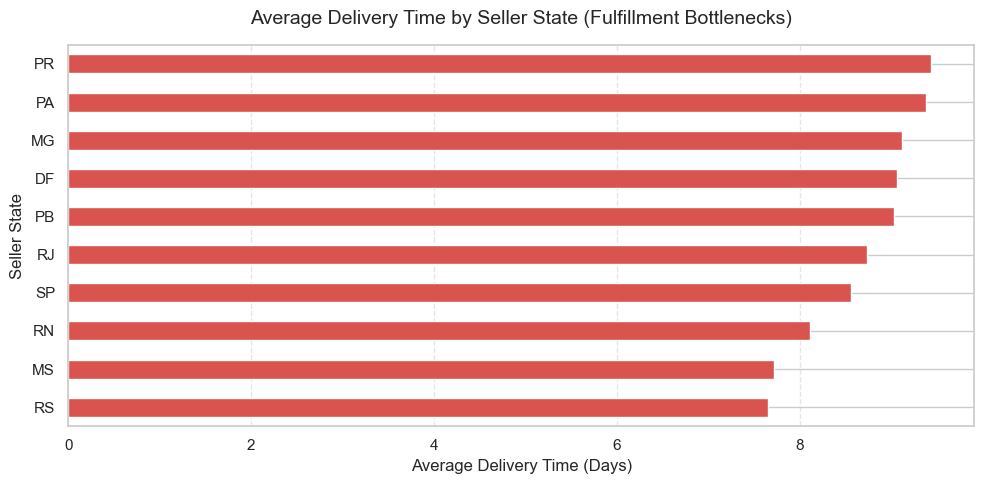

In [243]:
plot_data = seller_geo_performance.sort_values(by='avg_delivery_time', ascending=True).head(10)

plt.figure(figsize=(5,5))
ax = plot_data.plot(
    kind='barh',
    x='seller_state',
    y='avg_delivery_time',
    figsize=(10, 5),
    color='#d9534f',
    legend=False,)

plt.title(
    'Average Delivery Time by Seller State (Fulfillment Bottlenecks)',fontsize=14,pad=15,)
plt.xlabel('Average Delivery Time (Days)')
plt.ylabel('Seller State')
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Customer Satisfaction analysis ###

In [244]:
order_items_products_sellers_orders_reviews=pd.merge(order_items_products_sellers_orders,order_reviews,on='order_id',how='inner')

### Average rating per state ###

In [245]:
order_items_products_sellers_orders_reviews.groupby('seller_state')['review_score'].mean().reset_index(name='Average rating')

,seller_state,Average rating
0,AC,1.000000
1,AM,2.333333
2,BA,4.092044
3,CE,4.138298
4,DF,4.032294
5,ES,4.005450
6,GO,4.253385
7,MA,4.000000
8,MG,4.106436
9,MS,4.469388


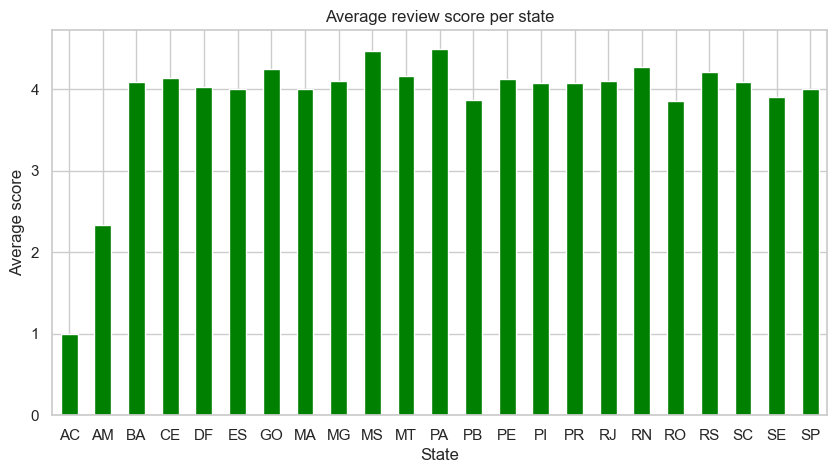

In [246]:
plt.figure(figsize=(10,5))
order_items_products_sellers_orders_reviews.groupby('seller_state')['review_score'].mean().plot(kind='bar',color='green')

plt.title('Average review score per state')
plt.xlabel('State')
plt.ylabel('Average score')
plt.xticks(rotation=0)
plt.show()

### Average rating per city (top 10 and bottom 10) ###

In [247]:
order_items_products_sellers_orders_reviews.groupby('seller_city')['review_score'].mean().sort_values(ascending=False).head(10).reset_index(name='avg review score')

,seller_city,avg review score
0,abadia de goias,5.0
1,uruguaiana,5.0
2,laguna,5.0
3,lambari,5.0
4,minas gerais,5.0
5,messias targino,5.0
6,tocantins,5.0
7,itaporanga,5.0
8,itapui,5.0
9,ivoti,5.0


In [248]:
order_items_products_sellers_orders_reviews.groupby('seller_city')['review_score'].mean().sort_values().head(10).reset_index(name='avg review score')

,seller_city,avg review score
0,soledade,1.0
1,rio branco,1.0
2,bom jesus dos perdoes,1.0
3,santo antonio da patrulha,1.0
4,pirassununga,1.0
5,orleans,1.0
6,ipua,1.0
7,carmo da mata,1.0
8,marapoama,1.0
9,miguelopolis,1.0


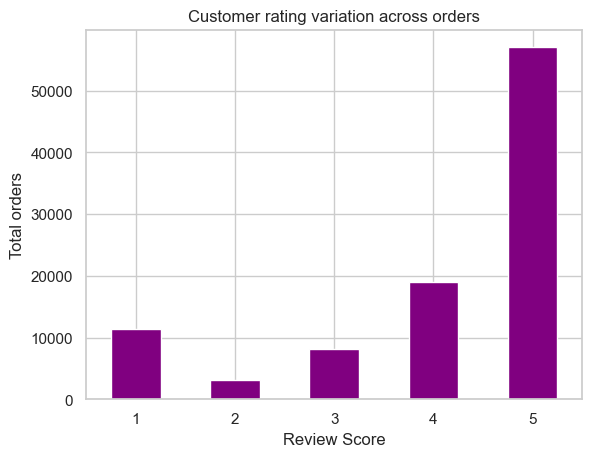

In [249]:
order_reviews.groupby('review_score')['order_id'].count().plot(kind='bar',color='purple')
plt.title('Customer rating variation across orders')
plt.xlabel('Review Score')
plt.ylabel('Total orders')
plt.xticks(rotation=0)
plt.show()

### Average rating by category (Top 10 categories) ###

In [250]:
rsumm2=order_items_products_sellers_orders_reviews.groupby('product_category_name_english')['review_score'].mean().sort_values(ascending=False).head(10).reset_index(name='average rating')
rsumm2

,product_category_name_english,average rating
0,cds_dvds_musicals,4.642857
1,fashion_childrens_clothes,4.500000
2,books_general_interest,4.446266
3,costruction_tools_tools,4.444444
4,flowers,4.419355
5,books_imported,4.400000
6,books_technical,4.363636
7,luggage_accessories,4.315257
8,food_drink,4.310469
9,small_appliances_home_oven_and_coffee,4.302632


### Average rating by category ( Bottom 10 ) ###

In [251]:
rsumm4=order_items_products_sellers_orders_reviews.groupby('product_category_name_english')['review_score'].mean().sort_values().head(10).reset_index(name='average rating')
rsumm4

,product_category_name_english,average rating
0,security_and_services,2.500000
1,diapers_and_hygiene,3.256410
2,office_furniture,3.491950
3,home_comfort_2,3.629630
4,fashion_male_clothing,3.641221
5,fixed_telephony,3.681992
6,fashio_female_clothing,3.750000
7,party_supplies,3.767442
8,furniture_mattress_and_upholstery,3.815789
9,home_confort,3.831019


### Average rating by time period ###

In [252]:
rsumm3=order_items_products_sellers_orders_reviews.groupby('order_purchase_period')['review_score'].mean().reset_index(name='Average rating')
rsumm3

,order_purchase_period,Average rating
0,2016-09,1.000000
1,2016-10,3.596639
2,2016-12,5.000000
3,2017-01,4.058263
4,2017-02,4.052062
5,2017-03,4.060525
6,2017-04,4.004134
7,2017-05,4.133545
8,2017-06,4.131853
9,2017-07,4.145536


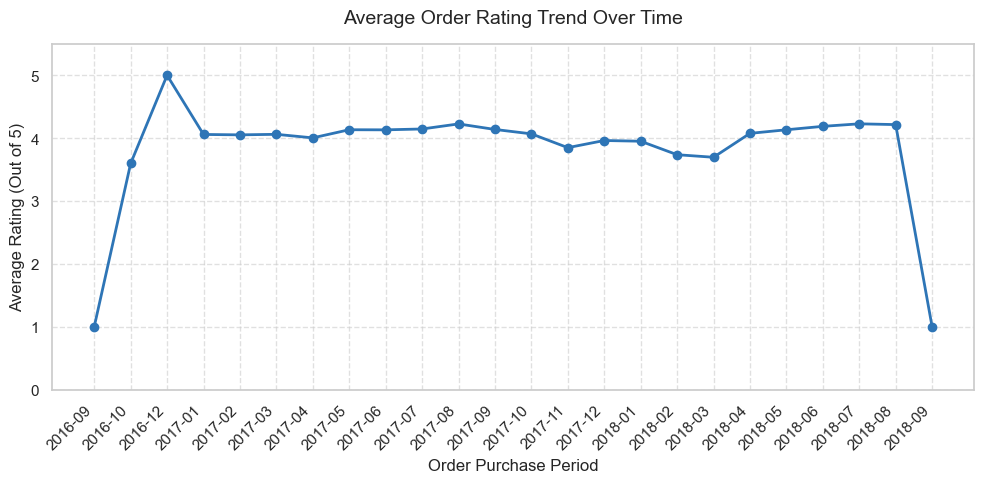

In [253]:
rsumm3['order_purchase_period'] =rsumm3['order_purchase_period'].astype(str)
plt.figure(figsize=(10,5))
plt.plot(
    rsumm3['order_purchase_period'],
    rsumm3['Average rating'],
    marker='o',
    color='#2e75b6',
    linewidth=2,
    markersize=6,)

plt.title('Average Order Rating Trend Over Time', fontsize=14, pad=15)
plt.xlabel('Order Purchase Period', fontsize=12)
plt.ylabel('Average Rating (Out of 5)', fontsize=12)

plt.xticks(rotation=45, ha='right')

plt.ylim(0, 5.5)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [254]:
seller_avg_rating = (order_items_products_sellers_orders_reviews.groupby('seller_id')['review_score'].mean().reset_index())
seller_avg_rating.rename(columns={'review_score': 'avg_review_score'}, inplace=True)

seller_avg_rating['rating_bucket'] = seller_avg_rating['avg_review_score'].round()

seller_rating_counts = (seller_avg_rating.groupby('rating_bucket')['seller_id'].count().reset_index())
seller_rating_counts.rename(columns={'seller_id': 'seller_count'}, inplace=True)

print(seller_rating_counts)

   rating_bucket  seller_count
0            1.0           157
1            2.0           123
2            3.0           307
3            4.0          1633
4            5.0           870


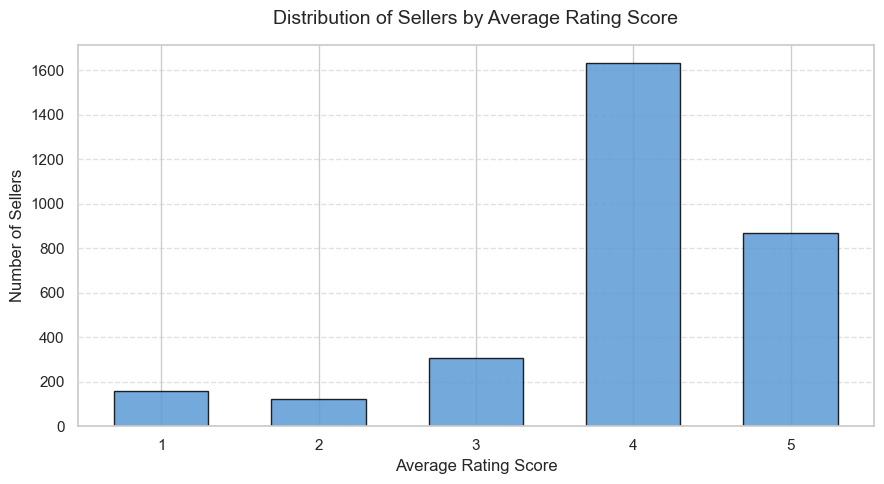

In [255]:
plt.figure(figsize=(9, 5))
plt.bar(
    seller_rating_counts['rating_bucket'],
    seller_rating_counts['seller_count'],
    color='#5b9bd5',
    edgecolor='black',
    alpha=0.85,
    width=0.6,)

plt.title('Distribution of Sellers by Average Rating Score', fontsize=14, pad=15)
plt.xlabel('Average Rating Score', fontsize=12)
plt.ylabel('Number of Sellers', fontsize=12)

plt.xticks([1, 2, 3, 4, 5])

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## End of EDA ##